In [1079]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# E-Commerce Intelligence & Revenue Analytics

In [1080]:
customers=pd.read_csv("../data/processed/customers_clean.csv")
geolocation=pd.read_csv("../data/processed/geolocation_clean.csv")
order_payment=pd.read_csv("../data/processed/order_payments_clean.csv")
order_reviews=pd.read_csv("../data/processed/order_reviews_clean.csv")
orders=pd.read_csv("../data/processed/orders_clean.csv")
order_items=pd.read_csv("../data/processed/orders_items_clean.csv")
product_category_name_translation=pd.read_csv("../data/processed/product_category_name_translation_clean.csv")
products=pd.read_csv("../data/processed/products_clean.csv")
sellers=pd.read_csv("../data/processed/sellers_clean.csv")

In [1081]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


In [1082]:
cols = ["review_creation_date", "review_answer_timestamp"]
for col in cols:
    order_reviews[col]=pd.to_datetime(order_reviews[col],errors="coerce")


In [1083]:
order_reviews.info()

<class 'pandas.DataFrame'>
RangeIndex: 99224 entries, 0 to 99223
Data columns (total 7 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   review_id                99224 non-null  str           
 1   order_id                 99224 non-null  str           
 2   review_score             99224 non-null  int64         
 3   review_comment_title     11568 non-null  str           
 4   review_comment_message   40950 non-null  str           
 5   review_creation_date     99224 non-null  datetime64[us]
 6   review_answer_timestamp  99224 non-null  datetime64[us]
dtypes: datetime64[us](2), int64(1), str(4)
memory usage: 5.3 MB


In [1084]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date,delivered_without_approval,invalid_approval_carrier_sequence,invalid_carrier_customer_sequence
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,False,False,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,False,False,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,False,False,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,False,False,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,False,False,False


In [1085]:
date_col=["order_purchase_timestamp",
          "order_approved_at",
          "order_delivered_carrier_date",
          "order_delivered_customer_date",
          "order_estimated_delivery_date"]
for col in date_col:
    orders[col]=pd.to_datetime(
        orders[col],
        errors="coerce"
    )

In [1086]:
orders.info()

<class 'pandas.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype         
---  ------                             --------------  -----         
 0   order_id                           99441 non-null  str           
 1   customer_id                        99441 non-null  str           
 2   order_status                       99441 non-null  str           
 3   order_purchase_timestamp           99441 non-null  datetime64[us]
 4   order_approved_at                  99281 non-null  datetime64[us]
 5   order_delivered_carrier_date       97658 non-null  datetime64[us]
 6   order_delivered_customer_date      96476 non-null  datetime64[us]
 7   order_estimated_delivery_date      99441 non-null  datetime64[us]
 8   invalid_delivery_date              99441 non-null  bool          
 9   canceled_with_delivery_date        99441 non-null  bool          
 10  delivered_without_approval         99441 non-

In [1087]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [1088]:
order_items["shipping_limit_date"]=pd.to_datetime(order_items["shipping_limit_date"])

In [1089]:
order_items.info()

<class 'pandas.DataFrame'>
RangeIndex: 112650 entries, 0 to 112649
Data columns (total 7 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   order_id             112650 non-null  str           
 1   order_item_id        112650 non-null  int64         
 2   product_id           112650 non-null  str           
 3   seller_id            112650 non-null  str           
 4   shipping_limit_date  112650 non-null  datetime64[us]
 5   price                112650 non-null  float64       
 6   freight_value        112650 non-null  float64       
dtypes: datetime64[us](1), float64(2), int64(1), str(3)
memory usage: 6.0 MB


In [1090]:
sellers

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
...,...,...,...,...
3090,98dddbc4601dd4443ca174359b237166,87111,sarandi,PR
3091,f8201cab383e484733266d1906e2fdfa,88137,palhoca,SC
3092,74871d19219c7d518d0090283e03c137,4650,sao paulo,SP
3093,e603cf3fec55f8697c9059638d6c8eb5,96080,pelotas,RS


In [1091]:
orders.head()

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date,delivered_without_approval,invalid_approval_carrier_sequence,invalid_carrier_customer_sequence
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,False,False,False
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,False,False,False,False
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,False,False,False,False
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,False,False,False
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,False,False,False,False


In [1092]:
orders["order_id"].nunique()


99441

In [1093]:
orders.groupby("order_status")["order_id"].nunique()

order_status
approved           2
canceled         625
created            5
delivered      96478
invoiced         314
processing       301
shipped         1107
unavailable      609
Name: order_id, dtype: int64

In [1094]:
percentage=(orders.groupby("order_status")["order_id"].nunique())/len(orders)*100

In [1095]:
percentage.sort_values(ascending=True)

order_status
approved        0.002011
created         0.005028
processing      0.302692
invoiced        0.315765
unavailable     0.612423
canceled        0.628513
shipped         1.113223
delivered      97.020344
Name: order_id, dtype: float64

### Business Insight — Order Status Distribution

Approximately 97.02% of all orders were delivered, indicating a high proportion of successful order fulfillment. Around 1.11% were shipped but not recorded as delivered. The remaining orders were distributed across canceled, unavailable, invoiced, processing, approved, and created statuses.

**Key takeaway:** The business demonstrates a strong delivery completion pattern, while the remaining order statuses provide opportunities to investigate cancellations, product availability, and fulfillment delays.

In [1096]:
orders["order_purchase_timestamp"]

0       2017-10-02 10:56:33
1       2018-07-24 20:41:37
2       2018-08-08 08:38:49
3       2017-11-18 19:28:06
4       2018-02-13 21:18:39
                ...        
99436   2017-03-09 09:54:05
99437   2018-02-06 12:58:58
99438   2017-08-27 14:46:43
99439   2018-01-08 21:28:27
99440   2018-03-08 20:57:30
Name: order_purchase_timestamp, Length: 99441, dtype: datetime64[us]

In [1097]:
orders["order_month"]=orders["order_purchase_timestamp"].dt.to_period("M")

In [1098]:
orders["order_month"]

0        2017-10
1        2018-07
2        2018-08
3        2017-11
4        2018-02
          ...   
99436    2017-03
99437    2018-02
99438    2017-08
99439    2018-01
99440    2018-03
Name: order_month, Length: 99441, dtype: period[M]

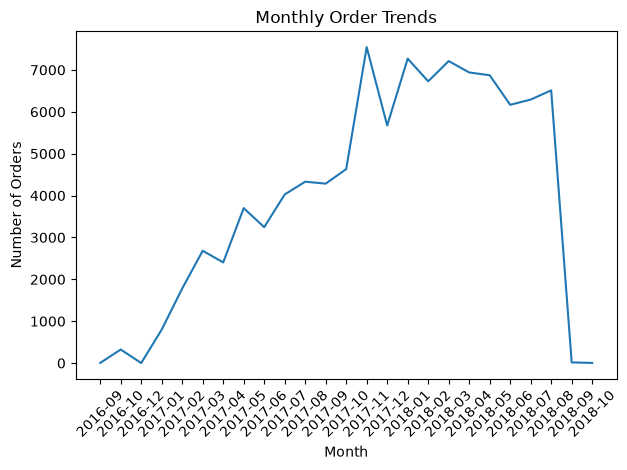

In [1099]:
monthly_orders=orders.groupby("order_month").size()
sns.lineplot(x=monthly_orders.index.astype(str),y=monthly_orders.values)

plt.title("Monthly Order Trends")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()

In [1100]:
monthly_orders.sort_values()

order_month
2016-12       1
2016-09       4
2018-10       4
2018-09      16
2016-10     324
2017-01     800
2017-02    1780
2017-04    2404
2017-03    2682
2017-06    3245
2017-05    3700
2017-07    4026
2017-09    4285
2017-08    4331
2017-10    4631
2017-12    5673
2018-06    6167
2018-07    6292
2018-08    6512
2018-02    6728
2018-05    6873
2018-04    6939
2018-03    7211
2018-01    7269
2017-11    7544
Freq: M, dtype: int64

### Business Insight — Monthly Order Trends

- The lowest order volume was recorded in December 2016, with just 1 order. This may be due to the dataset starting near the end of the month.
- November 2017 recorded the highest order volume, with 7,544 orders.
- Monthly order volumes varied throughout the observed period, indicating changes in customer purchasing activity.

**Key takeaway:** November 2017 was the peak month for order volume in the dataset.

In [1101]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [1102]:
merged=pd.merge(order_items,orders,on="order_id",how="left")
merged["price + freight"]=merged["price"]+merged["freight_value"]
monthly_revenue=merged.groupby("order_month")["price + freight"].sum()

In [1103]:
monthly_revenue

order_month
2016-09        354.75
2016-10      56808.84
2016-12         19.62
2017-01     137188.49
2017-02     286280.62
2017-03     432048.59
2017-04     412422.24
2017-05     586190.95
2017-06     502963.04
2017-07     584971.62
2017-08     668204.60
2017-09     720398.91
2017-10     769312.37
2017-11    1179143.77
2017-12     863547.23
2018-01    1107301.89
2018-02     986908.96
2018-03    1155126.82
2018-04    1159698.04
2018-05    1149781.82
2018-06    1022677.11
2018-07    1058728.03
2018-08    1003308.47
2018-09        166.46
Freq: M, Name: price + freight, dtype: float64

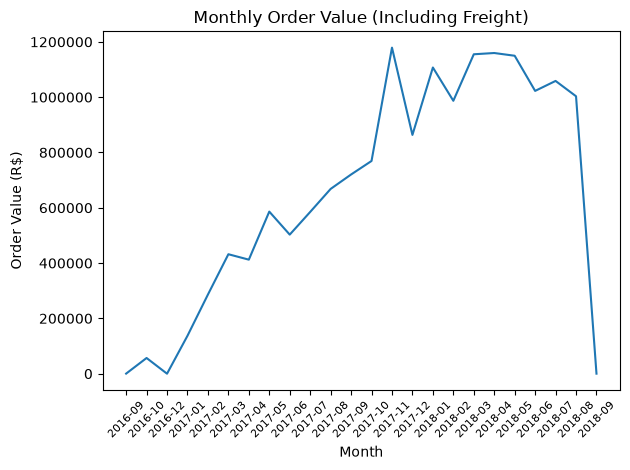

In [1104]:
sns.lineplot(x=monthly_revenue.index.astype(str),y=monthly_revenue.values)
plt.title("Monthly Order Value (Including Freight)")
plt.xlabel("Month")
plt.ylabel("Order Value (R$)")
plt.xticks(rotation=45,fontsize=8)
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()


### Monthly Order Value Analysis

- Monthly order value generally increased throughout 2017.
- November 2017 recorded the highest order value (~R$1.18 million).
- Order value fluctuated during 2018.
- September 2018 showed a sharp decline, possibly due to incomplete monthly data.

**Conclusion:** Order value showed strong growth in 2017, followed by fluctuations in 2018.

In [1105]:
monthly_comparison = pd.merge(
    monthly_orders.reset_index(),
    monthly_revenue.reset_index(),
    on="order_month"
)

In [1106]:
monthly_comparison

,order_month,0,price + freight
0,2016-09,4,354.75
1,2016-10,324,56808.84
2,2016-12,1,19.62
3,2017-01,800,137188.49
4,2017-02,1780,286280.62
5,2017-03,2682,432048.59
6,2017-04,2404,412422.24
7,2017-05,3700,586190.95
8,2017-06,3245,502963.04
9,2017-07,4026,584971.62


In [1107]:
monthly_comparison.rename(columns={0: "Total_orders","price + freight":"order_value"}, inplace=True)

C:\Users\Harsha K R\AppData\Local\Temp\ipykernel_2128\3025827689.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  monthly_comparison.rename(columns={0: "Total_orders","price + freight":"order_value"}, inplace=True)


In [1108]:
monthly_comparison.sort_values(by="Total_orders",ascending=False)

,order_month,Total_orders,order_value
13,2017-11,7544,1179143.77
15,2018-01,7269,1107301.89
17,2018-03,7211,1155126.82
18,2018-04,6939,1159698.04
19,2018-05,6873,1149781.82
16,2018-02,6728,986908.96
22,2018-08,6512,1003308.47
21,2018-07,6292,1058728.03
20,2018-06,6167,1022677.11
14,2017-12,5673,863547.23


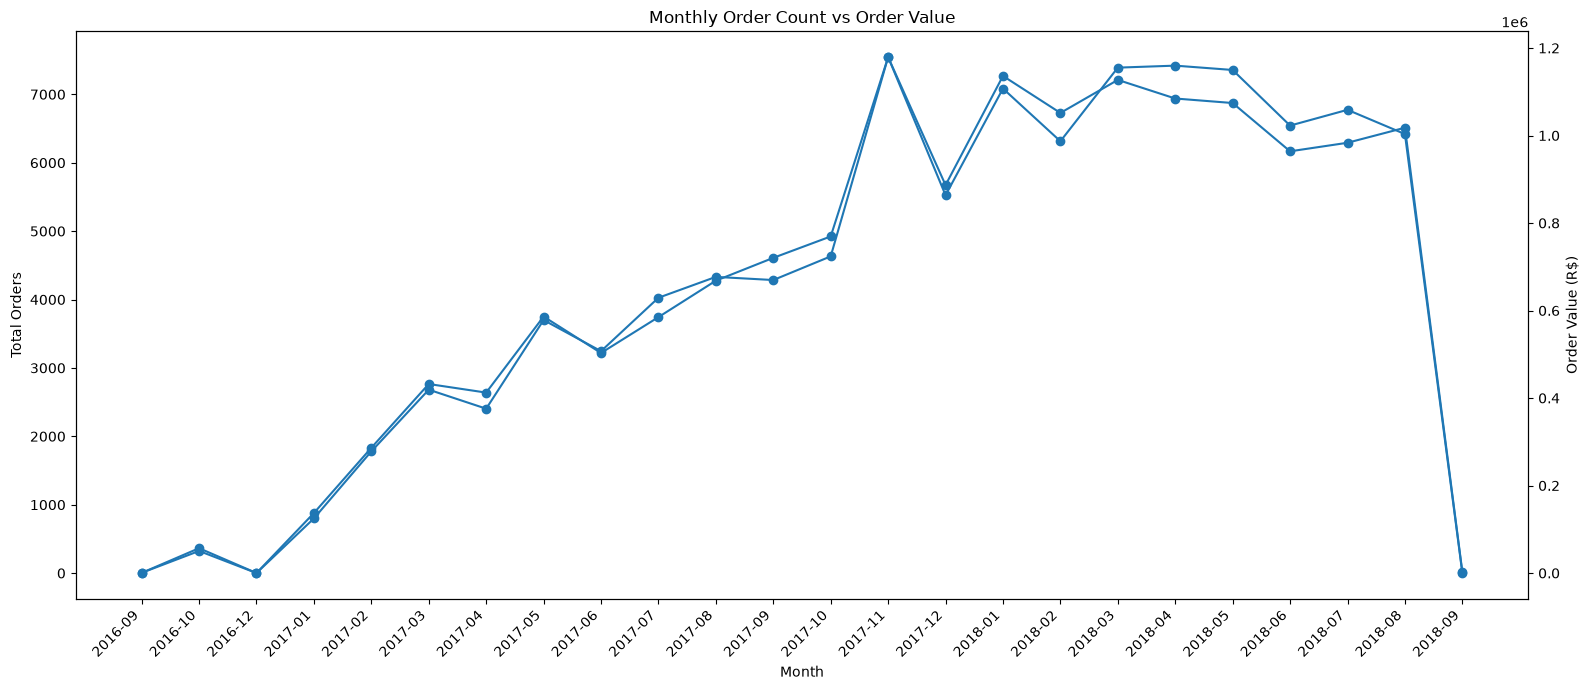

In [1109]:
fig, ax1 = plt.subplots(figsize=(16,7))

# Monthly order count
ax1.plot(monthly_comparison["order_month"].astype(str),
         monthly_comparison["Total_orders"],
         marker="o")

ax1.set_xlabel("Month")
ax1.set_ylabel("Total Orders")

# Monthly order value
ax2 = ax1.twinx()

ax2.plot(monthly_comparison["order_month"].astype(str),
         monthly_comparison["order_value"],
         marker="o")

ax2.set_ylabel("Order Value (R$)")

plt.title("Monthly Order Count vs Order Value")
plt.setp(ax1.get_xticklabels(), rotation=45, ha="right")

plt.tight_layout()
plt.show()

<Axes: xlabel='Total_orders', ylabel='order_value'>

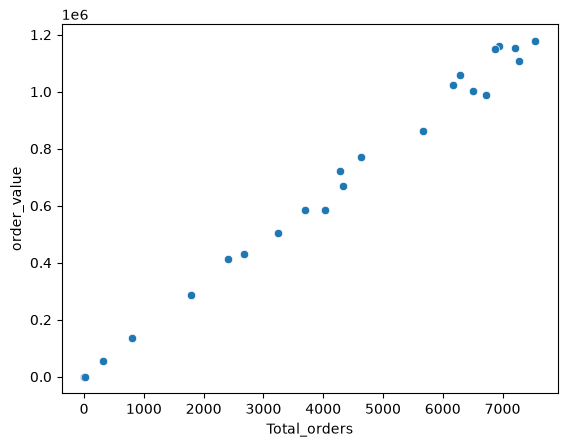

In [1110]:
sns.scatterplot(data=monthly_comparison,x="Total_orders",y="order_value")

In [1111]:
monthly_comparison[["Total_orders", "order_value"]].corr()

,Total_orders,order_value
Total_orders,1.00000,0.99612
order_value,0.99612,1.00000


### Monthly Order Count vs Order Value

- Order count and order value generally increased together during 2017.
- November 2017 recorded the highest order count.
- Both metrics fluctuated during 2018.
- September 2018 shows a sharp decline, possibly due to incomplete data.

**Conclusion:** Monthly order count and order value appear to have a positive relationship.

### Correlation: Monthly Orders vs Order Value

- The correlation coefficient is **0.99612**.
- This indicates an extremely strong positive correlation between monthly order count and order value.
- Months with higher order counts generally have higher order values.

**Conclusion:** Monthly order volume and total order value have a very strong positive linear relationship.

In [1112]:
products.head()

,product_id,product_category_name,product_name_length,product_description_length,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0


In [1113]:
category_sales=pd.merge(order_items[["product_id","price"]],products[["product_id","product_category_name"]],on="product_id",how="left")

In [1114]:
category_sales

,product_id,price,product_category_name
0,4244733e06e7ecb4970a6e2683c13e61,58.90,cool_stuff
1,e5f2d52b802189ee658865ca93d83a8f,239.90,pet_shop
2,c777355d18b72b67abbeef9df44fd0fd,199.00,moveis_decoracao
3,7634da152a4610f1595efa32f14722fc,12.99,perfumaria
4,ac6c3623068f30de03045865e4e10089,199.90,ferramentas_jardim
...,...,...,...
112645,4aa6014eceb682077f9dc4bffebc05b0,299.99,utilidades_domesticas
112646,32e07fd915822b0765e448c4dd74c828,350.00,informatica_acessorios
112647,72a30483855e2eafc67aee5dc2560482,99.90,esporte_lazer
112648,9c422a519119dcad7575db5af1ba540e,55.99,informatica_acessorios


In [1115]:
category_sales.groupby("product_category_name").size().sort_values()

product_category_name
seguros_e_servicos                   2
fashion_roupa_infanto_juvenil        8
pc_gamer                             9
cds_dvds_musicais                   14
la_cuisine                          14
                                 ...  
informatica_acessorios            7827
moveis_decoracao                  8334
esporte_lazer                     8641
beleza_saude                      9670
cama_mesa_banho                  11115
Length: 73, dtype: int64

In [1116]:
category_avg_price=category_sales.groupby("product_category_name")["price"].mean().sort_values()

In [1117]:
category_revenue=category_sales.groupby("product_category_name")["price"].sum().sort_values(ascending=False)

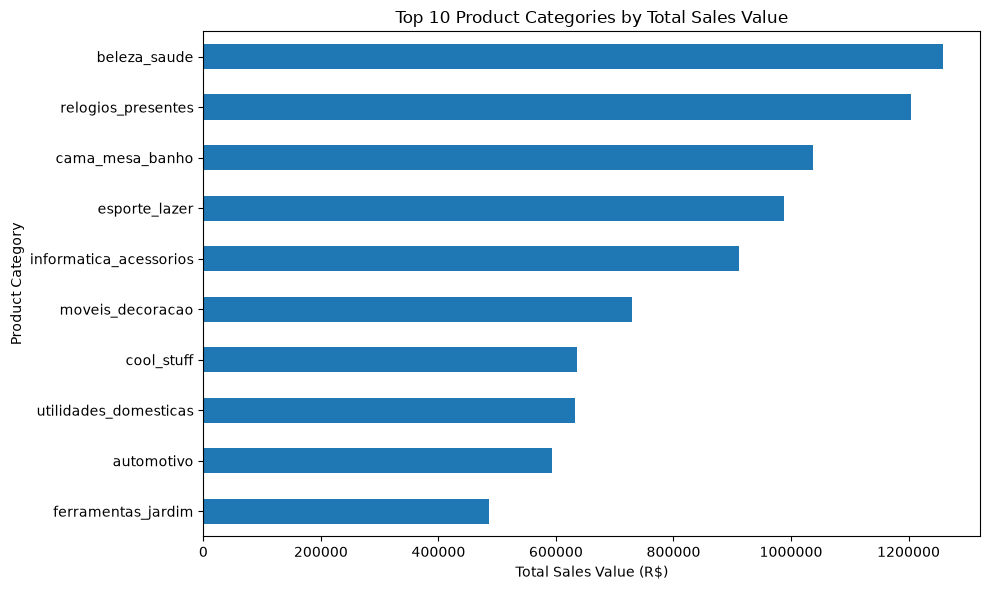

In [1118]:
top_10_categories = category_revenue.head(10).sort_values()

plt.figure(figsize=(10, 6))
top_10_categories.plot(kind="barh")

plt.title("Top 10 Product Categories by Total Sales Value")
plt.xlabel("Total Sales Value (R$)")
plt.ylabel("Product Category")
plt.ticklabel_format(axis="x", style="plain")
plt.tight_layout()
plt.show()

### Product Category Sales Performance

- `beleza_saude` recorded the highest total product sales value, approximately R$1.26 million.
- `relogios_presentes` ranked second, followed by `cama_mesa_banho`.
- `esporte_lazer` and `informatica_acessorios` also generated substantial sales value.
- The top 10 categories show considerable differences in their total sales contributions.

**Conclusion:** The beauty and health category generated the highest product sales value among all categories.

**Note:** Sales value is calculated using product prices (`price`) and excludes freight charges.


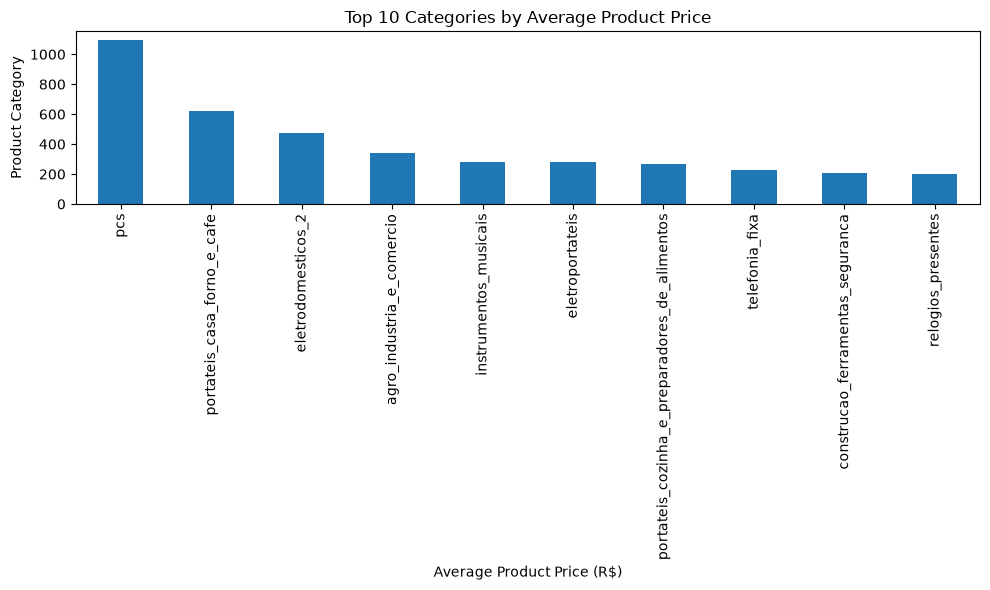

In [1119]:
top_10_avg_price=category_avg_price.sort_values(ascending=False).head(10)
top_10_avg_price.plot(kind='bar',figsize=(10,6))
plt.title("Top 10 Categories by Average Product Price")
plt.xlabel("Average Product Price (R$)")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### Average Product Price by Category

- `pcs` has the highest average product price at approximately R$1,098.34.
- `portateis_casa_forno_e_cafe` ranks second at approximately R$624.29.
- `eletrodomesticos_2` ranks third at approximately R$476.12.
- Categories such as `instrumentos_musicais` and `eletroportateis` also have relatively high average prices.

**Conclusion:** The `pcs` category has a considerably higher average product price than the other top 10 categories.

**Note:** Average product price is calculated using the mean of the `price` column for each category.

In [1120]:
order_items["product_id"].nunique()

32951

In [1121]:
order_items.shape

(112650, 7)

In [1122]:
products["product_category_name"].nunique()

73

In [1123]:
category_items_sold=(category_sales.groupby("product_category_name").size().sort_values(ascending=False))

In [1124]:
category_items_sold.head(10)

product_category_name
cama_mesa_banho           11115
beleza_saude               9670
esporte_lazer              8641
moveis_decoracao           8334
informatica_acessorios     7827
utilidades_domesticas      6964
relogios_presentes         5991
telefonia                  4545
ferramentas_jardim         4347
automotivo                 4235
dtype: int64

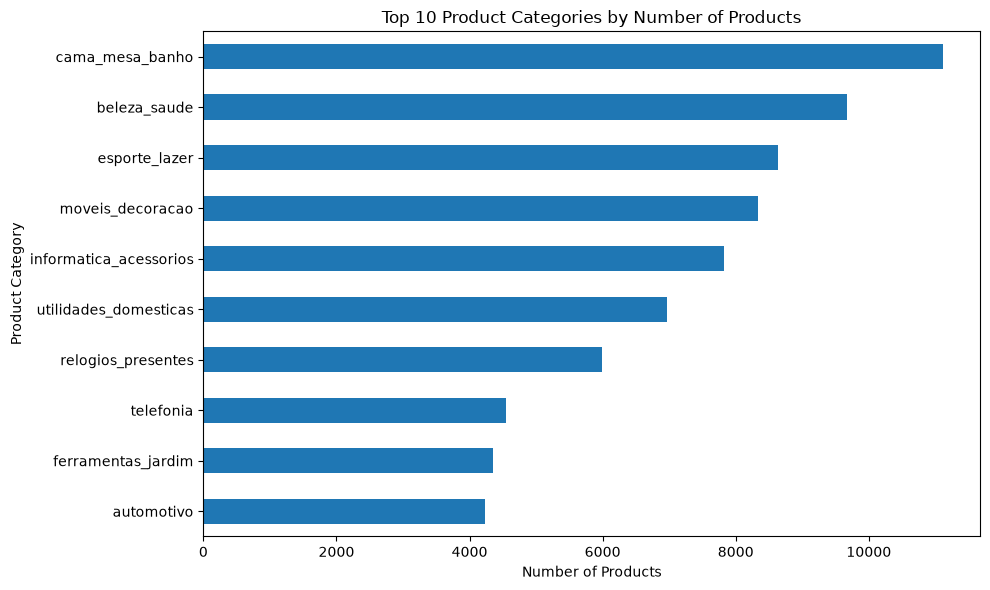

In [1125]:
top_10_products = category_items_sold.head(10).sort_values()

top_10_products.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Product Categories by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")
plt.tight_layout()
plt.show()

### Product Distribution by Category

- `cama_mesa_banho` has the highest number of listed products, with 11,115 products.
- `beleza_saude` ranks second with 9,670 products.
- `esporte_lazer` and `moveis_decoracao` also have a large product catalog.
- The top 10 categories show that product distribution varies considerably across categories.

**Conclusion:** `cama_mesa_banho` has the largest product catalog among the categories, followed by `beleza_saude` and `esporte_lazer`.

**Note:** Product counts represent records in the product catalog, not the number of items sold.

In [1126]:
customers.head()

,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


In [1127]:
customer_by_state=(customers.groupby("customer_state").size().sort_values(ascending=False))

In [1128]:
customer_by_state

customer_state
SP    41746
RJ    12852
MG    11635
RS     5466
PR     5045
SC     3637
BA     3380
DF     2140
ES     2033
GO     2020
PE     1652
CE     1336
PA      975
MT      907
MA      747
MS      715
PB      536
PI      495
RN      485
AL      413
SE      350
TO      280
RO      253
AM      148
AC       81
AP       68
RR       46
dtype: int64

In [1129]:
customers["customer_state"].nunique()

27

In [1130]:
unique_customers_by_state = (
    customers.groupby("customer_state")["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

unique_customers_by_state.head(10)

customer_state
SP    40302
RJ    12384
MG    11259
RS     5277
PR     4882
SC     3534
BA     3277
DF     2075
ES     1964
GO     1952
Name: customer_unique_id, dtype: int64

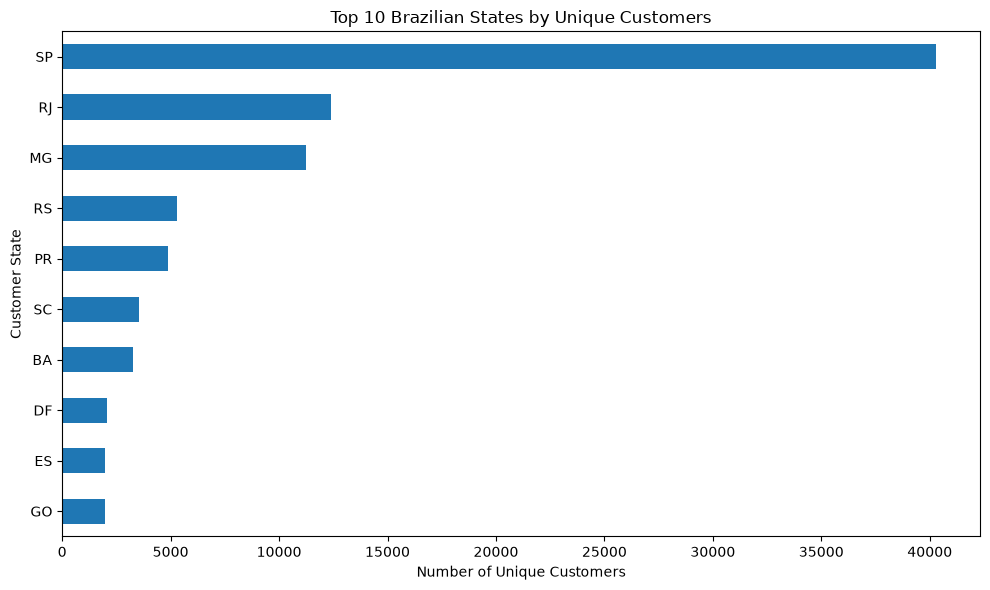

In [1131]:
top_10_states = unique_customers_by_state.head(10).sort_values()

top_10_states.plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Brazilian States by Unique Customers")
plt.xlabel("Number of Unique Customers")
plt.ylabel("Customer State")
plt.tight_layout()
plt.show()

### Customer Distribution by State

- São Paulo (SP) has the highest number of unique customers, with 40,302.
- Rio de Janeiro (RJ) ranks second with 12,384 unique customers.
- Minas Gerais (MG) ranks third with 11,259 unique customers.
- Customer distribution varies considerably across Brazilian states.

**Conclusion:** São Paulo is the leading state in terms of unique customer count, followed by Rio de Janeiro and Minas Gerais.

**Note:** Unique customers are counted using `customer_unique_id` to avoid counting the same customer multiple times within a state.

In [1132]:
customers['customer_city'].nunique()

4119

In [1133]:
customer_by_city=(customers.groupby('customer_city')["customer_unique_id"].nunique().sort_values(ascending=False))

In [1134]:
customer_by_city.head(10)

customer_city
sao paulo                14984
rio de janeiro            6620
belo horizonte            2672
brasilia                  2069
curitiba                  1465
campinas                  1398
porto alegre              1326
salvador                  1209
guarulhos                 1153
sao bernardo do campo      908
Name: customer_unique_id, dtype: int64

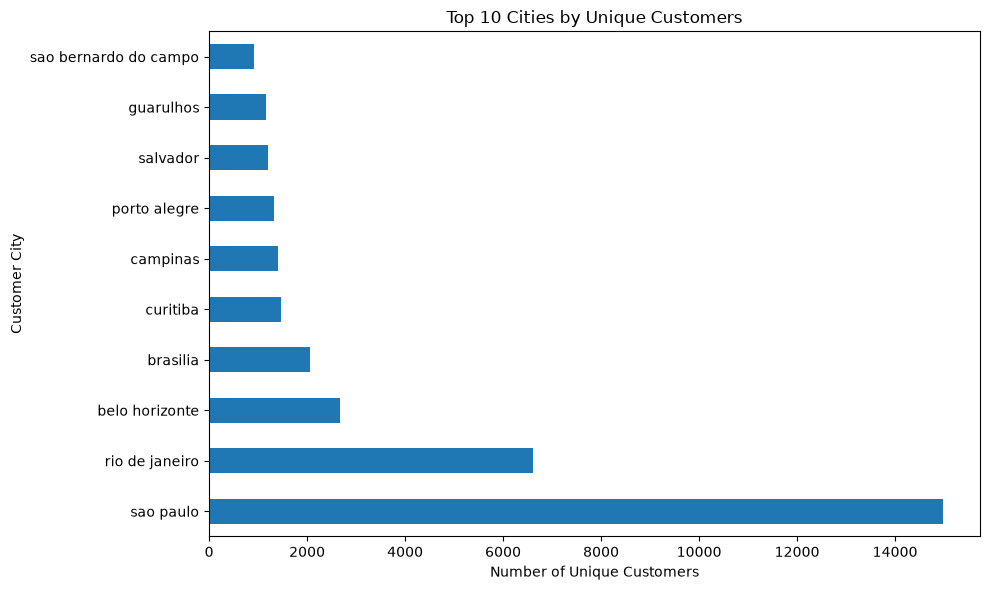

In [1135]:
to_10_cities=customer_by_city.head(10).sort_values(ascending=False)
to_10_cities.plot(kind="barh",figsize=(10,6))
plt.title("Top 10 Cities by Unique Customers")
plt.xlabel("Number of Unique Customers")
plt.ylabel("Customer City")
plt.tight_layout()
plt.show()

### Customer Distribution by City

- São Paulo has the highest number of unique customers, with 14,984.
- Rio de Janeiro ranks second with 6,620 unique customers.
- Belo Horizonte ranks third with 2,672 unique customers.
- São Paulo has more than twice the unique customer count of Rio de Janeiro.
- Customer distribution is concentrated in a few major Brazilian cities.

**Conclusion:** São Paulo is the leading city in terms of unique customer count, followed by Rio de Janeiro.

**Note:** Unique customers are counted using `customer_unique_id`.

In [1136]:
order_payment.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [1137]:
order_payment["order_id"].duplicated().sum()

np.int64(4446)

In [1138]:
order_payment.groupby("payment_type")["order_id"].count().sort_values(ascending=False)

payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: order_id, dtype: int64

In [1139]:
payments_type_count=(order_payment.groupby("payment_type")["order_id"].count().sort_values(ascending=False))/order_payment["order_id"].count()*100

In [1140]:
payments_type_count

payment_type
credit_card    73.922376
boleto         19.043952
voucher         5.558978
debit_card      1.471806
not_defined     0.002888
Name: order_id, dtype: float64

In [1141]:
order_payment.count()

order_id                103886
payment_sequential      103886
payment_type            103886
payment_installments    103886
payment_value           103886
dtype: int64

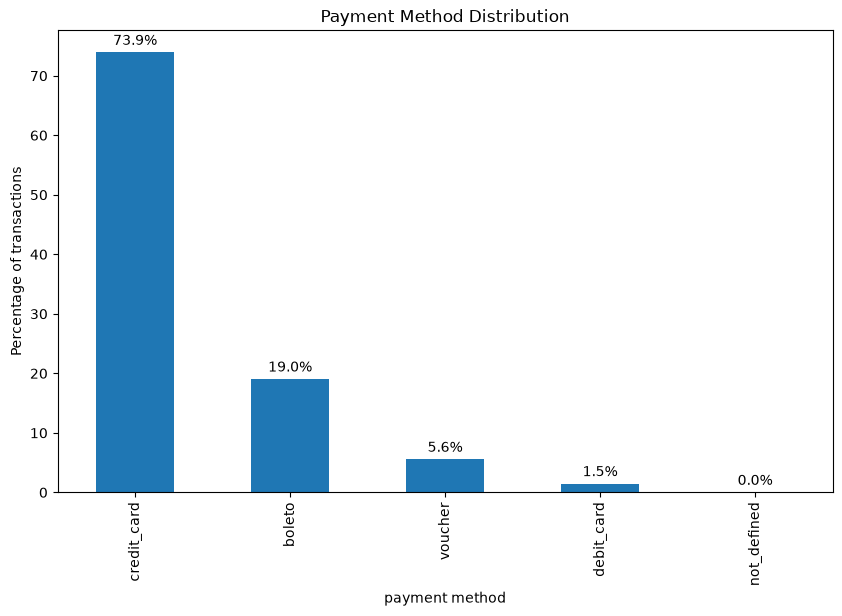

In [1142]:
ax=payments_type_count.plot(kind="bar",figsize=(10,6))
ax.bar_label(ax.containers[0],fmt="%.1f%%",padding=3)
plt.title("Payment Method Distribution")
plt.xlabel("payment method")
plt.ylabel("Percentage of transactions")

plt.show()

In [1143]:
order_payment.head()

,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


In [1144]:
payment_type_value=(order_payment.groupby("payment_type")["payment_value"].sum().sort_values(ascending=False))

In [1145]:
payment_type_value

payment_type
credit_card    12542084.19
boleto          2869361.27
voucher          379436.87
debit_card       217989.79
not_defined           0.00
Name: payment_value, dtype: float64

(array([0, 1, 2, 3, 4]),
 [Text(0, 0, 'credit_card'),
  Text(1, 0, 'boleto'),
  Text(2, 0, 'voucher'),
  Text(3, 0, 'debit_card'),
  Text(4, 0, 'not_defined')])

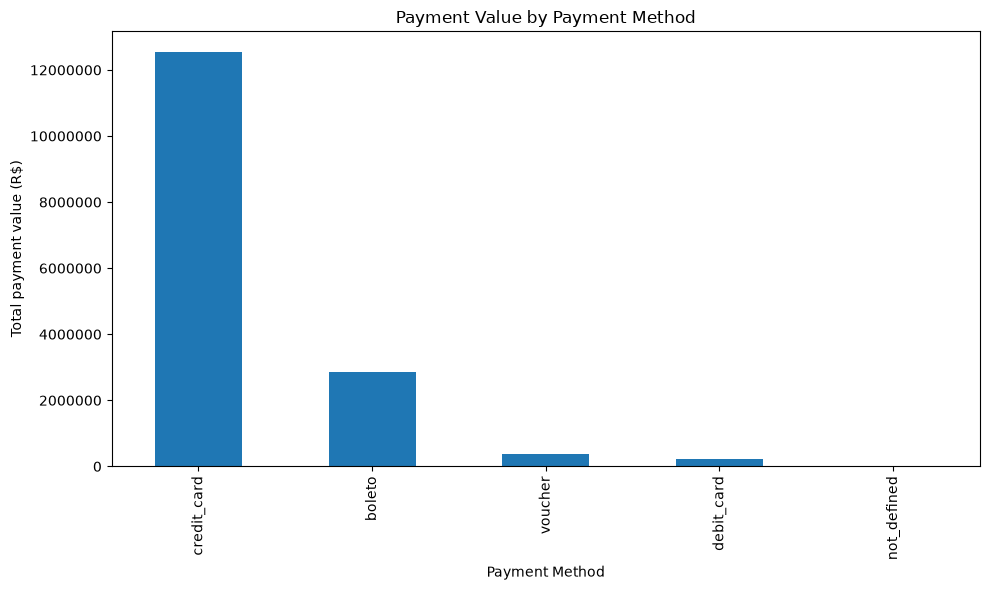

In [1146]:
payment_type_value.plot(kind="bar",figsize=(10,6))
plt.title("Payment Value by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Total payment value (R$)")
plt.ticklabel_format(axis="y", style="plain")
plt.tight_layout()
plt.xticks()

### Total Payment Value by Payment Method

- Credit cards generated the highest total payment value, approximately R$12.54 million.
- Boleto ranked second, contributing approximately R$2.87 million.
- Voucher payments contributed approximately R$379,437.
- Debit card payments contributed approximately R$217,990.
- The `not_defined` category recorded zero payment value.

**Conclusion:** Credit cards are the dominant payment method in terms of both transaction count and total payment value.

In [1147]:
payment_type_value_avg=(order_payment.groupby("payment_type")["payment_value"].mean().sort_values(ascending=False))

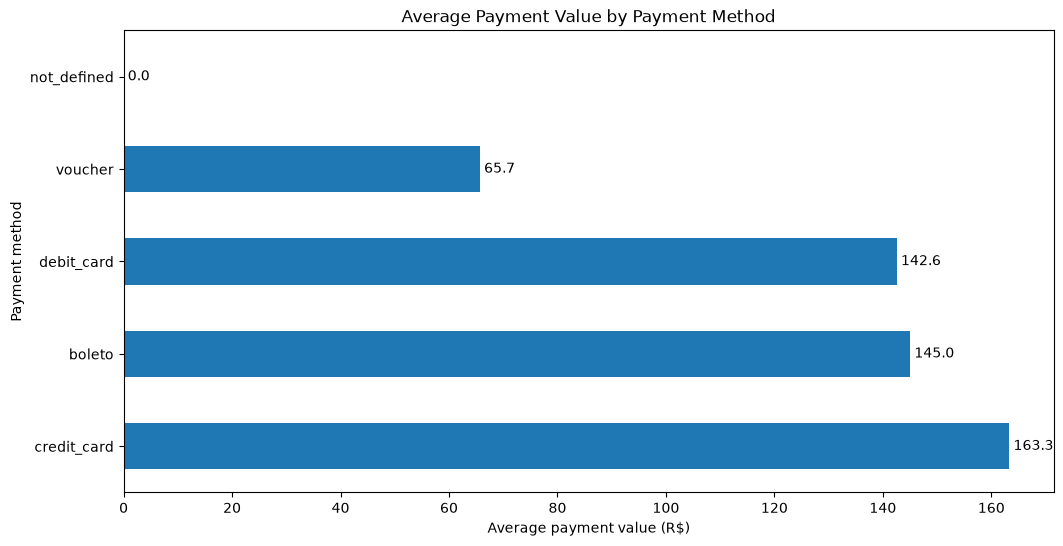

In [1148]:
ax=payment_type_value_avg.plot(kind="barh",figsize=(12,6))
ax.bar_label(ax.containers[0],fmt="%.1f",padding=3)
plt.title("Average Payment Value by Payment Method")
plt.ylabel("Payment method")
plt.xlabel("Average payment value (R$)")
plt.show()

### Average Payment Value by Payment Method

- Credit cards have the highest average payment value at approximately R$163.32.
- Boleto ranks second at approximately R$145.03.
- Debit cards have an average payment value of approximately R$142.57.
- Vouchers have a lower average payment value of approximately R$65.70.
- The `not_defined` category has an average payment value of zero.

**Conclusion:** Credit card transactions have the highest average payment value among the payment methods.

**Note:** Average payment value is calculated using the mean of `payment_value` for each payment type.

In [1149]:
order_reviews.head()

,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01,2018-03-02 10:26:53


In [1150]:
review_count=(order_reviews.groupby("review_score")["review_id"].count())/order_reviews["review_id"].count()*100

In [1151]:
review_count

review_score
1    11.513344
2     3.175643
3     8.242965
4    19.291704
5    57.776344
Name: review_id, dtype: float64

Text(0.5, 0, 'Review percentage')

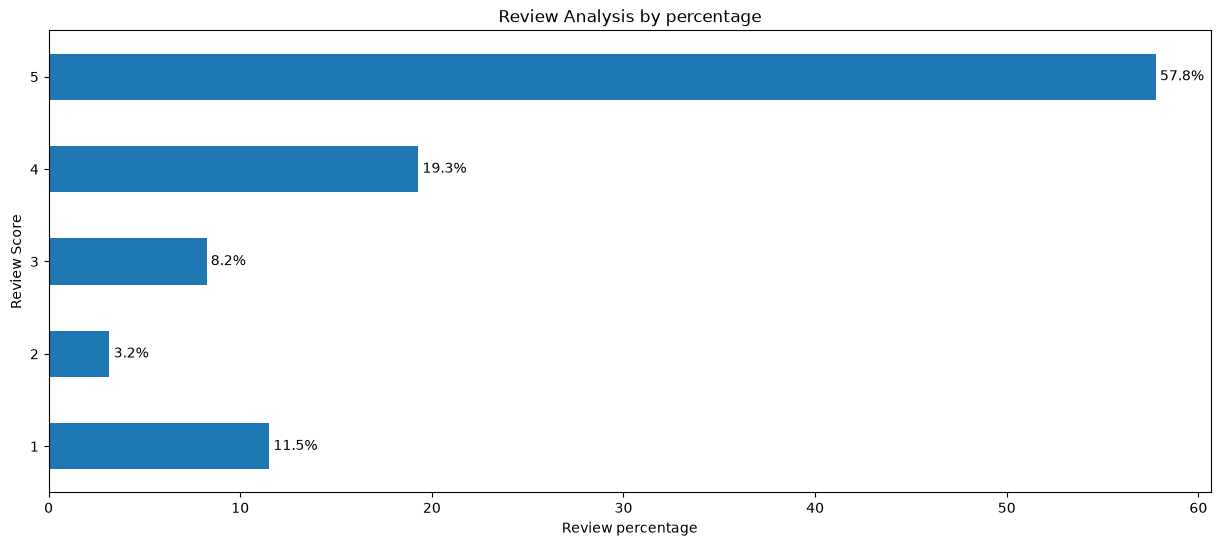

In [1152]:
ax=review_count.plot(kind="barh",figsize=(15,6))
ax.bar_label(ax.containers[0],fmt="%.1f%%",padding=3)
plt.title("Review Analysis by percentage")
plt.ylabel("Review Score")
plt.xlabel("Review percentage")

### Customer Review Score Distribution

- 5-star reviews account for the highest share, at approximately 57.8%.
- 4-star reviews contribute 19.3%.
- 3-star reviews represent 8.2%.
- 1-star and 2-star reviews account for 11.5% and 3.2%, respectively.
- Positive reviews (4 and 5 stars) represent approximately 77.1% of all reviews.

**Conclusion:** The review distribution indicates that most customers gave positive ratings, with 5-star reviews being the most common.

In [1153]:
order_reviews["review_score"].mean()

np.float64(4.08642062404257)

### Descriptive Statistics of Customer Reviews

- **Mean:** 4.08, indicating a relatively high average customer rating.
- **Median:** 5, showing that the middle review falls in the highest rating category.
- **Mode:** 5, indicating that 5-star reviews are the most frequently occurring ratings.

**Conclusion:** Customer ratings are generally positive, with an average score of 4.08 and both the median and mode equal to 5.

In [1154]:
low_reviews=order_reviews.groupby("review_score")["review_id"].count().head(2)

In [1155]:
low_reviews_percentage=low_reviews/order_reviews["review_id"].count()*100

In [1156]:
low_reviews.sum()

np.int64(14575)

In [1157]:
low_reviews_percentage.sum()

np.float64(14.688986535515602)

In [1158]:
order_reviews[(order_reviews["review_score"]<=2) & (order_reviews["review_comment_message"].isnull())].shape[0]/order_reviews[(order_reviews["review_score"]<=2) & (order_reviews["review_comment_message"])].shape[0]*100

C:\Users\Harsha K R\AppData\Local\Temp\ipykernel_2128\4142641576.py:1: Pandas4Warning: 'and' operations between boolean dtype and str are deprecated and will raise in a future version. Explicitly cast the strings to a boolean dtype before operating instead.
  order_reviews[(order_reviews["review_score"]<=2) & (order_reviews["review_comment_message"].isnull())].shape[0]/order_reviews[(order_reviews["review_score"]<=2) & (order_reviews["review_comment_message"])].shape[0]*100


25.289879931389365

In [1159]:
low_score_reviews=order_reviews[["review_id","review_comment_message"]][(order_reviews["review_score"]<=2) & (order_reviews["review_comment_message"].notna())]

In [1160]:
low_score_reviews["review_comment_message"]=low_score_reviews["review_comment_message"].str.lower()

In [1161]:
low_score_reviews

,review_id,review_comment_message
16,9314d6f9799f5bfba510cc7bcd468c01,"gostaria de saber o que houve, sempre recebi e..."
19,373cbeecea8286a2b66c97b1b157ec46,péssimo
29,2c5e27fc178bde7ac173c9c62c31b070,não gostei ! comprei gato por lebre
32,58044bca115705a48fe0e00a21390c54,sempre compro pela internet e a entrega ocorre...
39,9fd59cd04b42f600df9f25e54082a8d1,nada de chegar o meu pedido.
...,...,...
99155,2fc8295a24978092328d3a329d22940e,eu recebi o seguinte email e preciso saber com...
99169,3450ec3bbabeb09a08b00fc72da87a30,boa tarde. \r\nnão recebo todos os produtos fa...
99200,2ee221b28e5b6fceffac59487ed39348,foto muito diferente principalmente a graninha...
99203,5085bc489aa6b58a29c4f922d59ff826,tive um problema na entrega em que o correio c...


In [1162]:
low_score_reviews["cleaned_comment"] = (
    low_score_reviews["review_comment_message"]
    .str.replace(r"[^a-zA-ZÀ-ÿ\s]", "", regex=True)
)

In [1163]:
low_score_reviews["cleaned_comment"] = (
    low_score_reviews["cleaned_comment"]
    .str.replace(r"\d+", "", regex=True)
)

In [1164]:
low_score_reviews["cleaned_comment"] = (
    low_score_reviews["cleaned_comment"]
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
)

In [1165]:
import nltk
from nltk.corpus import stopwords

nltk.download("stopwords")

portuguese_stopwords = set(stopwords.words("portuguese"))

[nltk_data] Downloading package stopwords to C:\Users\Harsha K
[nltk_data]     R\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [1166]:
portuguese_stopwords.difference_update(["não", "nunca", "nem", "jamais"])

In [1167]:
low_score_reviews["cleaned_comment"] = low_score_reviews["cleaned_comment"].apply(
    lambda text: " ".join(
        word for word in text.split()
        if word not in portuguese_stopwords
    )
)

In [1168]:
import unicodedata
def remove_accents(text):
    return ''.join(
        char for char in unicodedata.normalize('NFKD', text)
        if not unicodedata.combining(char)
    )
low_score_reviews["cleaned_comment"] = low_score_reviews["cleaned_comment"].apply(remove_accents)

In [1169]:
low_score_reviews["tokens"] = low_score_reviews["cleaned_comment"].apply(
    lambda text: text.split()
)


In [1170]:
low_score_reviews["tokens"].head(5)

16    [gostaria, saber, sempre, recebi, compra, agor...
19                                            [pessimo]
29                  [nao, gostei, comprei, gato, lebre]
32    [sempre, compro, internet, entrega, ocorre, an...
39                               [nada, chegar, pedido]
Name: tokens, dtype: object

In [1171]:
from collections import Counter

In [1172]:
all_words = [word for tokens in low_score_reviews["tokens"] for word in tokens]
word_counts = Counter(all_words)

In [1173]:
word_counts.most_common(20)

[('nao', 8377),
 ('produto', 6129),
 ('recebi', 3261),
 ('comprei', 1863),
 ('veio', 1537),
 ('entrega', 1393),
 ('ainda', 1386),
 ('entregue', 1316),
 ('chegou', 1167),
 ('compra', 896),
 ('prazo', 896),
 ('pedido', 779),
 ('loja', 764),
 ('dia', 757),
 ('agora', 684),
 ('apenas', 538),
 ('nem', 514),
 ('nada', 508),
 ('produtos', 508),
 ('pois', 504)]

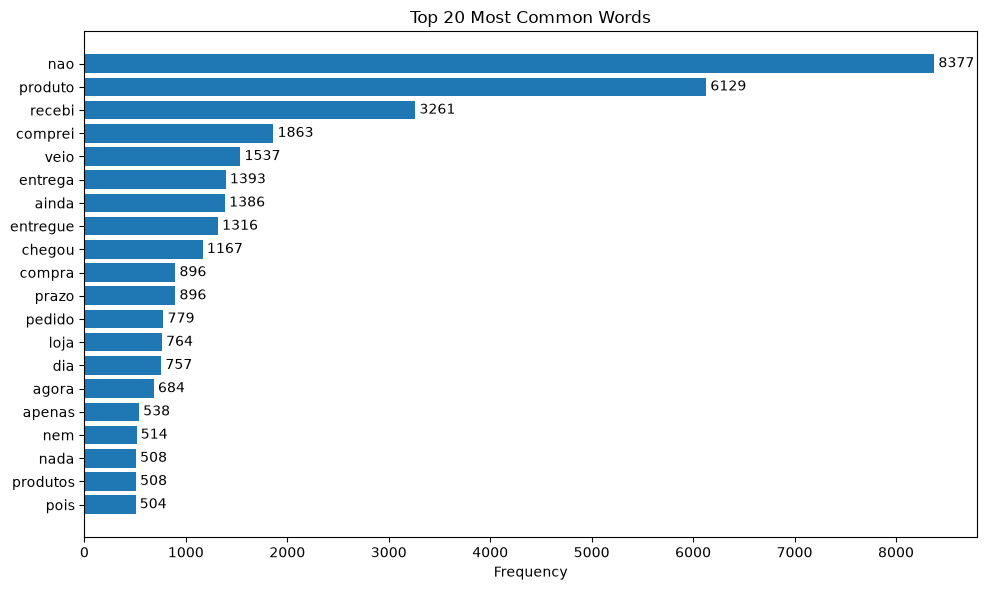

In [1174]:
top_words = word_counts.most_common(20)
words, counts = zip(*top_words)

fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(words, counts)

# Put the highest count at the top and add integer labels
ax.invert_yaxis()
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)

ax.set_xlabel("Frequency")
ax.set_title("Top 20 Most Common Words")
plt.tight_layout()
plt.show()

In [1175]:
print(type(word_counts), len(word_counts))


<class 'collections.Counter'> 10053


In [1176]:
from collections import Counter

bigram_counts = Counter(
    (tokens[i], tokens[i+1])
    for tokens in low_score_reviews["tokens"]
    for i in range(len(tokens)-1)
)

In [1177]:
bigram_counts.most_common(20)

[(('nao', 'recebi'), 1829),
 (('recebi', 'produto'), 1190),
 (('produto', 'nao'), 930),
 (('ainda', 'nao'), 833),
 (('nao', 'entregue'), 553),
 (('nao', 'chegou'), 545),
 (('produto', 'veio'), 321),
 (('nao', 'recomendo'), 282),
 (('agora', 'nao'), 257),
 (('nota', 'fiscal'), 252),
 (('prazo', 'entrega'), 234),
 (('comprei', 'produto'), 219),
 (('produto', 'ainda'), 218),
 (('nao', 'gostei'), 206),
 (('recebi', 'apenas'), 206),
 (('produto', 'entregue'), 186),
 (('momento', 'nao'), 177),
 (('nao', 'consigo'), 174),
 (('nao', 'veio'), 170),
 (('comprei', 'dois'), 166)]

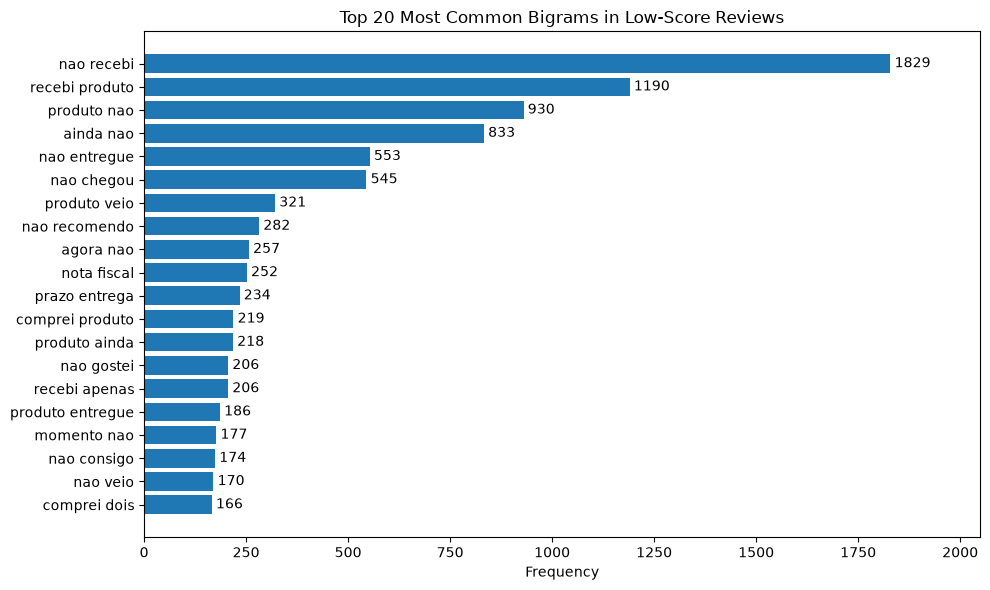

In [1178]:
top_bigrams = bigram_counts.most_common(20)

# 2. Convert ('nao', 'recebi') -> 'nao recebi' and extract counts
bigrams = [" ".join(pair) for pair, count in top_bigrams]
counts = [count for pair, count in top_bigrams]

# 3. Plot the horizontal bar chart
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(bigrams, counts)

ax.invert_yaxis()  # Put the highest count ('nao recebi') at the top
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
ax.set_xlim(0, max(counts) * 1.12)  # Prevent label cutoff on the right

ax.set_xlabel("Frequency")
ax.set_title("Top 20 Most Common Bigrams in Low-Score Reviews")
plt.tight_layout()
plt.show()

## Order Review Analysis

### 1. Review Score Distribution
- 5-star reviews: 57.8%
- 4-star reviews: 19.3%
- 3-star reviews: 8.2%
- 2-star reviews: 3.2%
- 1-star reviews: 11.5%

**Observations:**
- Approximately 77.1% of reviews received 4 or 5 stars.
- Approximately 14.68% received 1 or 2 stars.
- The majority of customers gave positive ratings.

### 2. Review Score Statistics

| Metric | Value |
|---|---:|
| Mean | 4.08 |
| Median | 5 |
| Mode | 5 |

**Observation:** The median and mode of 5 indicate that the most common customer rating was highly positive.

### 3. Low-Score Review Analysis

Reviews with scores of 1 and 2 were considered low-score reviews.

- Total low-score reviews: 14,575
- Reviews with written comments: 10,889
- Reviews without written comments: 3,686

**Observations:**
- Approximately 25.29% of low-score reviews had no written comments.
- Approximately 74.71% contained written feedback.

### 4. Portuguese Review Text Analysis

Portuguese comments from low-score reviews were processed through:
- Lowercase conversion
- Punctuation and special-character removal
- Number removal
- Whitespace normalization
- Portuguese stopword removal, while preserving important negation words
- Accent normalization
- Tokenization

### 5. Word Frequency Analysis

The most frequent words included:
- `nao` – 8,377
- `produto` – 6,129
- `recebi` – 3,261
- `comprei` – 1,863
- `veio` – 1,537
- `entrega` – 1,393

**Observations:**
Frequent words suggest potential dissatisfaction related to products, order receipt and delivery.

### 6. Bigram Analysis

The most frequent bigrams included:
- `nao recebi` – 1,829
- `recebi produto` – 1,190
- `produto nao` – 930
- `ainda nao` – 833
- `nao entregue` – 553
- `nao chegou` – 545

**Observations:**
Order non-receipt and delivery-related issues appear frequently in low-score review comments.

*Note: These bigrams were generated after stopword removal, so some word pairs may not have been adjacent in the original comments.*

### Overall Conclusion

The review analysis shows that customer ratings were generally positive, but a meaningful proportion of customers gave low ratings. Text analysis of low-score reviews suggests recurring concerns involving order receipt, delivery and product dissatisfaction. These findings identify potential areas for further investigation but do not establish the underlying causes.

In [1179]:
sellers.head(10)

,seller_id,seller_zip_code_prefix,seller_city,seller_state
0,3442f8959a84dea7ee197c632cb2df15,13023,campinas,SP
1,d1b65fc7debc3361ea86b5f14c68d2e2,13844,mogi guacu,SP
2,ce3ad9de960102d0677a81f5d0bb7b2d,20031,rio de janeiro,RJ
3,c0f3eea2e14555b6faeea3dd58c1b1c3,4195,sao paulo,SP
4,51a04a8a6bdcb23deccc82b0b80742cf,12914,braganca paulista,SP
5,c240c4061717ac1806ae6ee72be3533b,20920,rio de janeiro,RJ
6,e49c26c3edfa46d227d5121a6b6e4d37,55325,brejao,PE
7,1b938a7ec6ac5061a66a3766e0e75f90,16304,penapolis,SP
8,768a86e36ad6aae3d03ee3c6433d61df,1529,sao paulo,SP
9,ccc4bbb5f32a6ab2b7066a4130f114e3,80310,curitiba,PR


In [1180]:
sellers.shape

(3095, 4)

In [1181]:
sellers["seller_id"].duplicated().sum()

np.int64(0)

In [1182]:
sellers.dtypes

seller_id                   str
seller_zip_code_prefix    int64
seller_city                 str
seller_state                str
dtype: object

In [1183]:
sellers_by_state=sellers.groupby("seller_state")["seller_id"].count().sort_values(ascending=False)

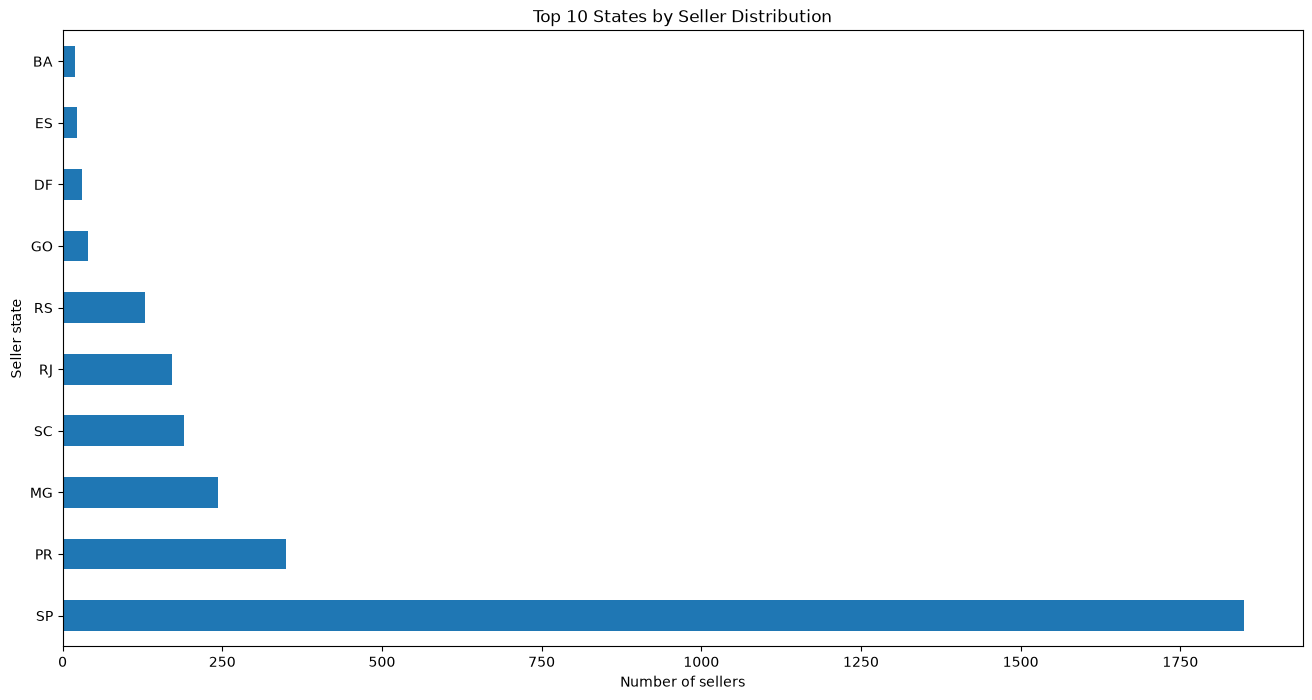

In [1184]:
sellers_by_state.head(10).plot(kind="barh",figsize=(16,8))
plt.title("Top 10 States by Seller Distribution")
plt.ylabel("Seller state")
plt.xlabel("Number of sellers")
plt.show()

In [1185]:
sellers_by_city=sellers.groupby("seller_city")["seller_id"].count().sort_values(ascending=False)

In [1186]:
sellers_by_city.head(20)

seller_city
sao paulo                694
curitiba                 127
rio de janeiro            96
belo horizonte            68
ribeirao preto            52
guarulhos                 50
ibitinga                  49
santo andre               45
campinas                  41
maringa                   40
sao jose do rio preto     33
sorocaba                  32
sao bernardo do campo     32
osasco                    32
porto alegre              28
brasilia                  28
londrina                  26
goiania                   23
joinville                 22
blumenau                  21
Name: seller_id, dtype: int64

In [1187]:
sellers_by_city.shape

(611,)

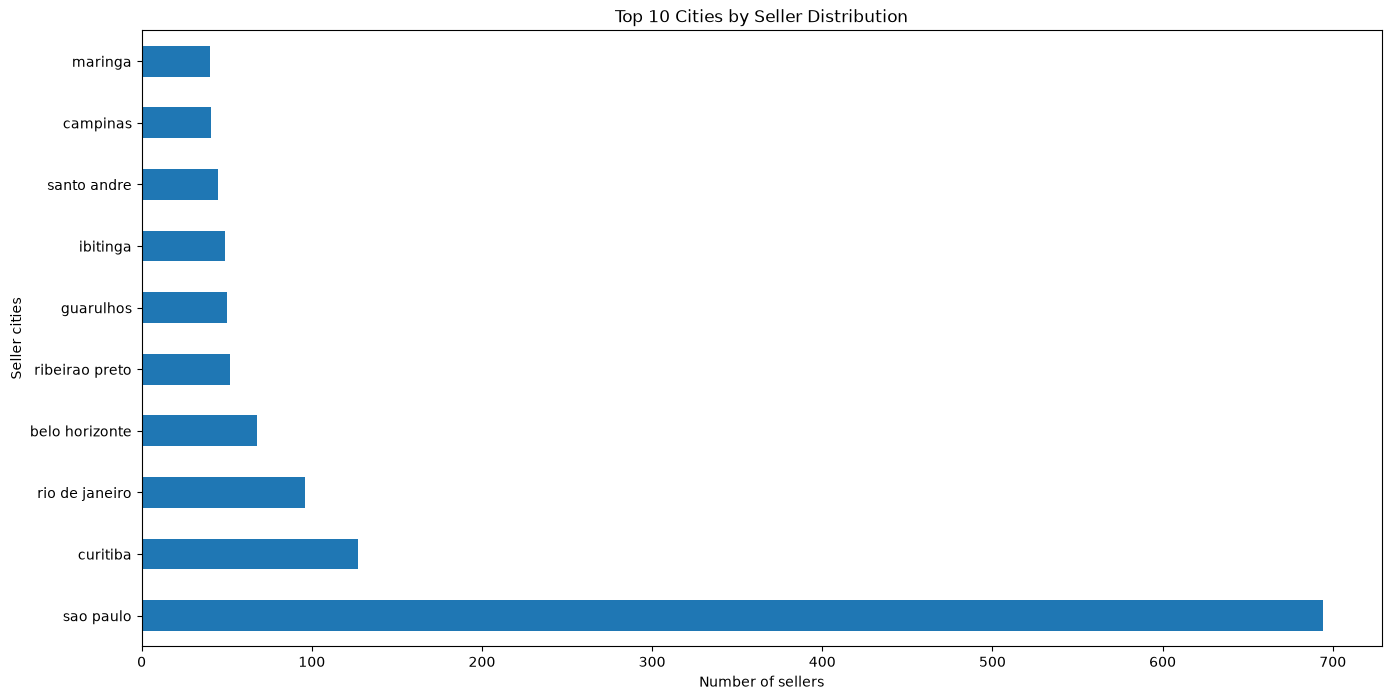

In [1188]:
sellers_by_city.head(10).plot(kind="barh",figsize=(16,8))
plt.title("Top 10 Cities by Seller Distribution")
plt.ylabel("Seller cities")
plt.xlabel("Number of sellers")
plt.show()

In [1189]:
top_seller_by_price_value=order_items.groupby("seller_id")["price"].sum()

Text(0.5, 0, 'Total product sales value (R$)')

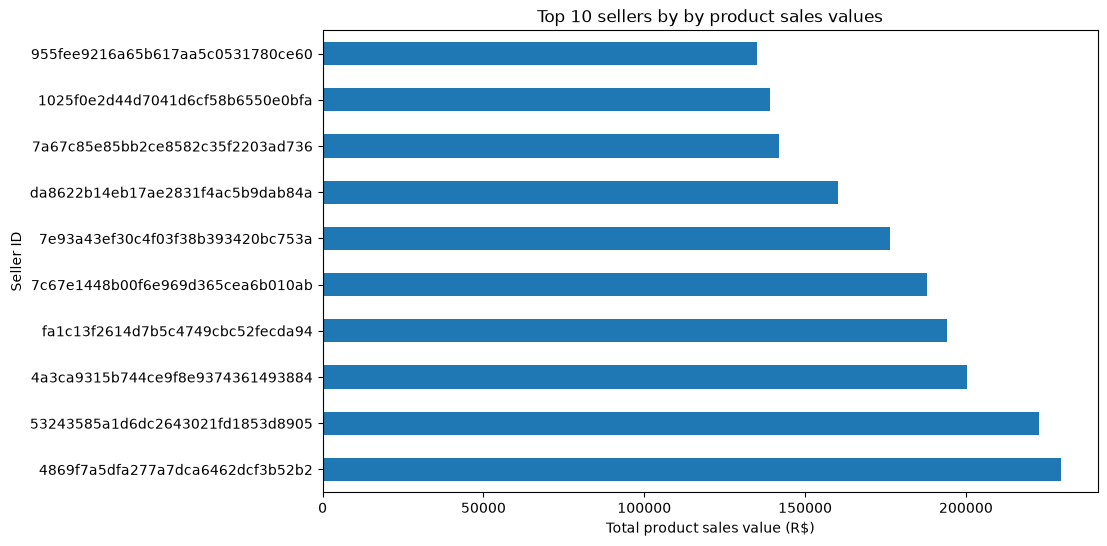

In [1190]:
top_seller_by_price_value.sort_values(ascending=False).head(10).plot(kind="barh",figsize=(10,6))
plt.title("Top 10 sellers by by product sales values")
plt.ylabel("Seller ID")
plt.xlabel("Total product sales value (R$)")

In [1191]:
order_items.head()

,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [1192]:
sellers_by_order_count=order_items.groupby("seller_id")["order_id"].nunique()

In [1193]:
sellers_by_order_count.sort_values(ascending=False).head(10)

seller_id
6560211a19b47992c3666cc44a7e94c0    1854
4a3ca9315b744ce9f8e9374361493884    1806
cc419e0650a3c5ba77189a1882b7556a    1706
1f50f920176fa81dab994f9023523100    1404
da8622b14eb17ae2831f4ac5b9dab84a    1314
955fee9216a65b617aa5c0531780ce60    1287
7a67c85e85bb2ce8582c35f2203ad736    1160
ea8482cd71df3c1969d7b9473ff13abc    1146
4869f7a5dfa277a7dca6462dcf3b52b2    1132
3d871de0142ce09b7081e2b9d1733cb1    1080
Name: order_id, dtype: int64

In [1194]:
order_items["order_id"].duplicated().sum()

np.int64(13984)

In [1195]:
sellers_by_avg_order_value=top_seller_by_price_value/sellers_by_order_count

In [1196]:
sellers_by_avg_order_value.sort_values(ascending=False).head(10)

seller_id
80ceebb4ee9b31afb6c6a916a574a1e2    6729.000000
ee27a8f15b1dded4d213a468ba4eb391    6499.000000
b37c4c02bda3161a7546a4e6d222d5b2    6018.750000
585175ec331ea177fa47199e39a6170a    3549.000000
abe021b01ba992245271b9aa422032df    3360.000000
a00824eb9093d40e589b940ec45c4eb0    3133.323333
e2a1ac9bf33e5549a2a4f834e70df2f8    2999.890000
e908c0f3646e8b60375734a350d95d71    2951.000000
d63c73efd41eb002280e7ec831424edb    2799.000000
1444c08e64d55fb3c25f0f09c07ffcf2    2749.000000
dtype: float64

Text(0.5, 0, 'Average value (R$)')

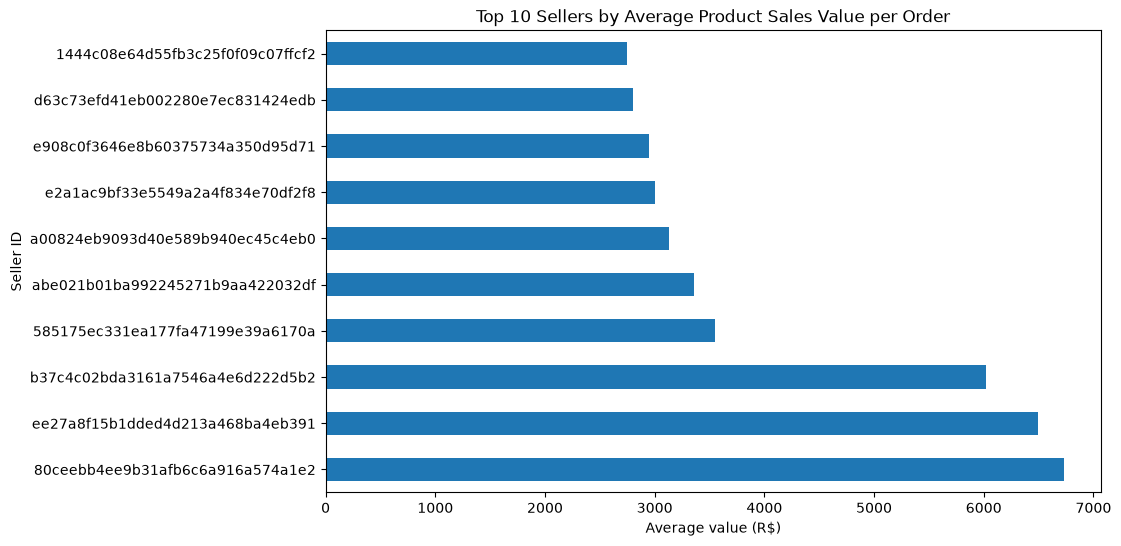

In [1197]:
sellers_by_avg_order_value.sort_values(ascending=False).head(10).plot(kind="barh",figsize=(10,6))
plt.title("Top 10 Sellers by Average Product Sales Value per Order")
plt.ylabel("Seller ID")
plt.xlabel("Average value (R$)")

### Average Product Sales Value per Seller

Seller `80ceebb4...` recorded the highest average product sales value per unique seller-order at **R$6,729**, followed by `ee27a8f1...` at **R$6,499**. Higher average order value does not necessarily mean higher overall sales performance, as order volume must also be considered.

*Note: Values exclude freight charges.*

In [1198]:
seller_performance=pd.concat([top_seller_by_price_value,sellers_by_order_count,sellers_by_avg_order_value],axis=1)

In [1199]:
seller_performance.rename(columns={"price":"total_sales","order_id":"unique_orders",0:"avg_order_value"},inplace=True)

C:\Users\Harsha K R\AppData\Local\Temp\ipykernel_2128\2897718978.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  seller_performance.rename(columns={"price":"total_sales","order_id":"unique_orders",0:"avg_order_value"},inplace=True)


In [1200]:
seller_performance.head()

,total_sales,unique_orders,avg_order_value
seller_id,,,
0015a82c2db000af6aaaf3ae2ecb0532,2685.00,3,895.000000
001cca7ae9ae17fb1caed9dfb1094831,25080.03,200,125.400150
001e6ad469a905060d959994f1b41e4f,250.00,1,250.000000
002100f778ceb8431b7a1020ff7ab48f,1234.50,51,24.205882
003554e2dce176b5555353e4f3555ac8,120.00,1,120.000000


In [1201]:
type(seller_performance)

pandas.DataFrame

Text(0, 0.5, 'total sales')

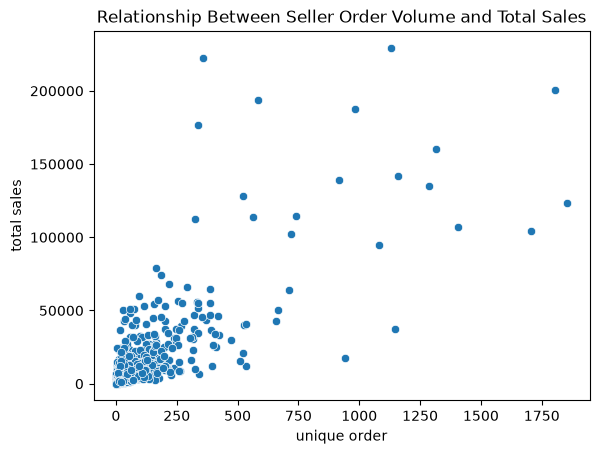

In [1202]:
sns.scatterplot(data=seller_performance,x="unique_orders",y="total_sales")
plt.title("Relationship Between Seller Order Volume and Total Sales")
plt.xlabel("unique order")
plt.ylabel("total sales")

### Seller Order Volume vs Total Sales

The scatter plot shows a generally positive relationship between seller order volume and total sales. Sellers with more orders tend to generate higher total sales, although considerable variation exists. Some sellers achieve high sales with fewer orders, indicating differences in average order value.

In [1203]:
seller_performance["unique_orders"].corr(seller_performance["total_sales"])

np.float64(0.7997018820029672)

### Correlation Between Seller Order Volume and Total Sales

The correlation coefficient is 0.7997, indicating a strong positive relationship between unique order count and total product sales. Sellers with higher order volumes generally tend to generate higher sales, although differences in average order value create some variation.

In [1204]:
top_sellers=seller_performance.sort_values(by="total_sales",ascending=False).head(10)

### Top 10 Sellers by Total Product Sales

Seller `4869f7a5...` recorded the highest total product sales at R$229,472.63. Seller `4a3ca931...` had the highest order volume with 1,806 unique orders, while seller `53243585...` achieved the highest average order value at R$622.28. This highlights differences in seller performance based on sales volume and average order value.

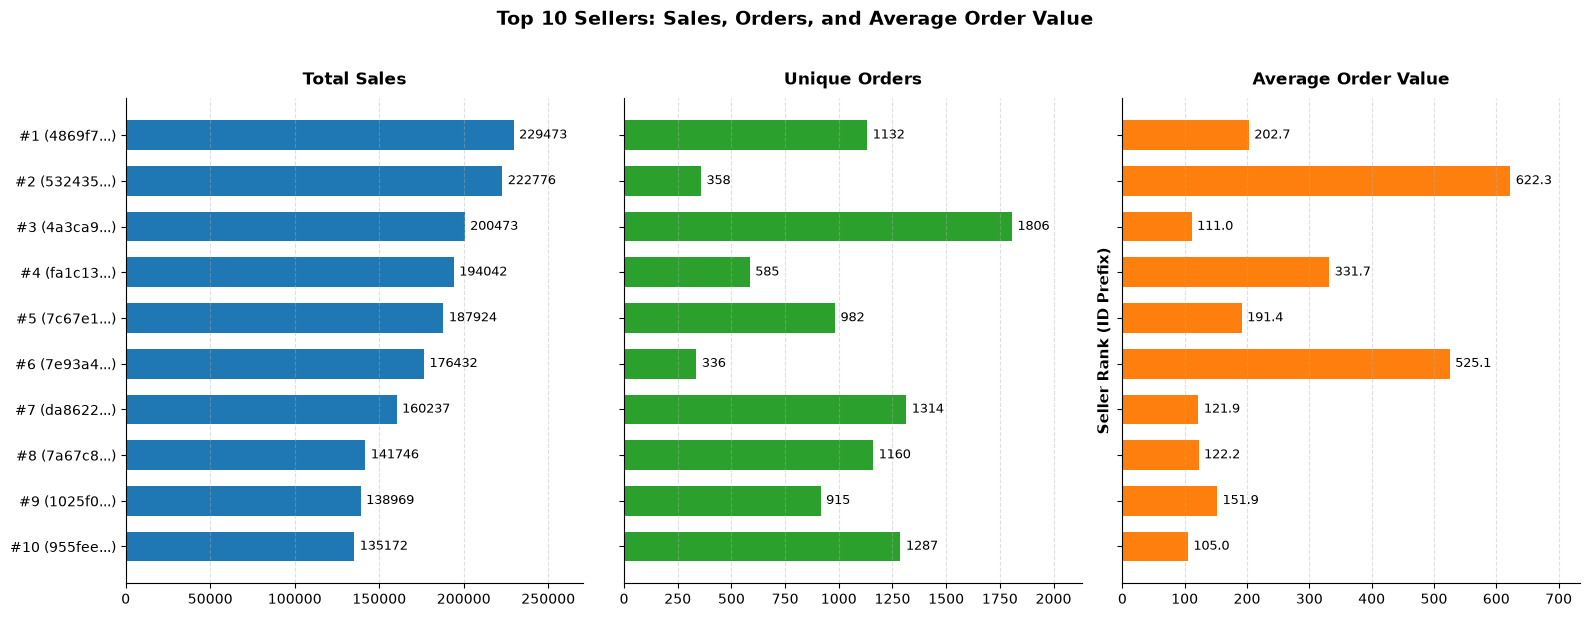

In [1205]:
import matplotlib.pyplot as plt

# Assuming your DataFrame is named `top_sellers`
# Sort ascending so the highest-selling seller sits at the top of the chart
df_plot = top_sellers.sort_values("total_sales", ascending=True).copy()

# Create short, readable y-axis labels from the 32-character index
# Reverses rank numbers so #1 is at the top
ranks = range(len(df_plot), 0, -1)
short_labels = [f"#{r} ({sid[:6]}...)" for r, sid in zip(ranks, df_plot.index)]

# Set up 3 side-by-side horizontal bar charts sharing the y-axis
fig, axes = plt.subplots(1, 3, figsize=(16, 6), sharey=True)

metrics = [
    ("total_sales", "Total Sales", "#1f77b4", "%.0f"),
    ("unique_orders", "Unique Orders", "#2ca02c", "%.0f"),
    ("avg_order_value", "Average Order Value", "#ff7f0e", "%.1f"),
]

for ax, (col, title, color, fmt) in zip(axes, metrics):
    bars = ax.barh(short_labels, df_plot[col], color=color, height=0.65)
    ax.set_title(title, fontsize=12, fontweight="bold", pad=10)
    
    # Add clean value labels (no % sign)
    ax.bar_label(bars, fmt=fmt, padding=4, fontsize=9)
    
    # Add 18% extra space on the right so labels never touch the border
    ax.set_xlim(0, df_plot[col].max() * 1.18)
    ax.grid(axis="x", linestyle="--", alpha=0.4)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

ax.set_ylabel("Seller Rank (ID Prefix)", fontsize=11, fontweight="bold")
plt.suptitle("Top 10 Sellers: Sales, Orders, and Average Order Value", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()


In [1206]:
seller_performance_with_state=order_items[["seller_id","price"]].merge(sellers[["seller_id","seller_state"]],on="seller_id")

In [1207]:
seller_performance_with_state.groupby(["seller_id","seller_state"],as_index=False)["price"].sum()

,seller_id,seller_state,price
0,0015a82c2db000af6aaaf3ae2ecb0532,SP,2685.00
1,001cca7ae9ae17fb1caed9dfb1094831,ES,25080.03
2,001e6ad469a905060d959994f1b41e4f,RJ,250.00
3,002100f778ceb8431b7a1020ff7ab48f,SP,1234.50
4,003554e2dce176b5555353e4f3555ac8,GO,120.00
...,...,...,...
3090,ffcfefa19b08742c5d315f2791395ee5,PR,69.90
3091,ffdd9f82b9a447f6f8d4b91554cc7dd3,PR,2101.20
3092,ffeee66ac5d5a62fe688b9d26f83f534,SP,1839.86
3093,fffd5413c0700ac820c7069d66d98c89,SP,9062.30


In [1208]:
sales_by_state = (
    seller_performance_with_state
    .groupby("seller_state")["price"]
    .sum()
    .sort_values(ascending=False)
)

sales_by_state.head(10)

seller_state
SP    8753396.21
PR    1261887.21
MG    1011564.74
RJ     843984.22
SC     632426.07
RS     378559.54
BA     285561.56
DF      97749.48
PE      91493.85
GO      66399.21
Name: price, dtype: float64

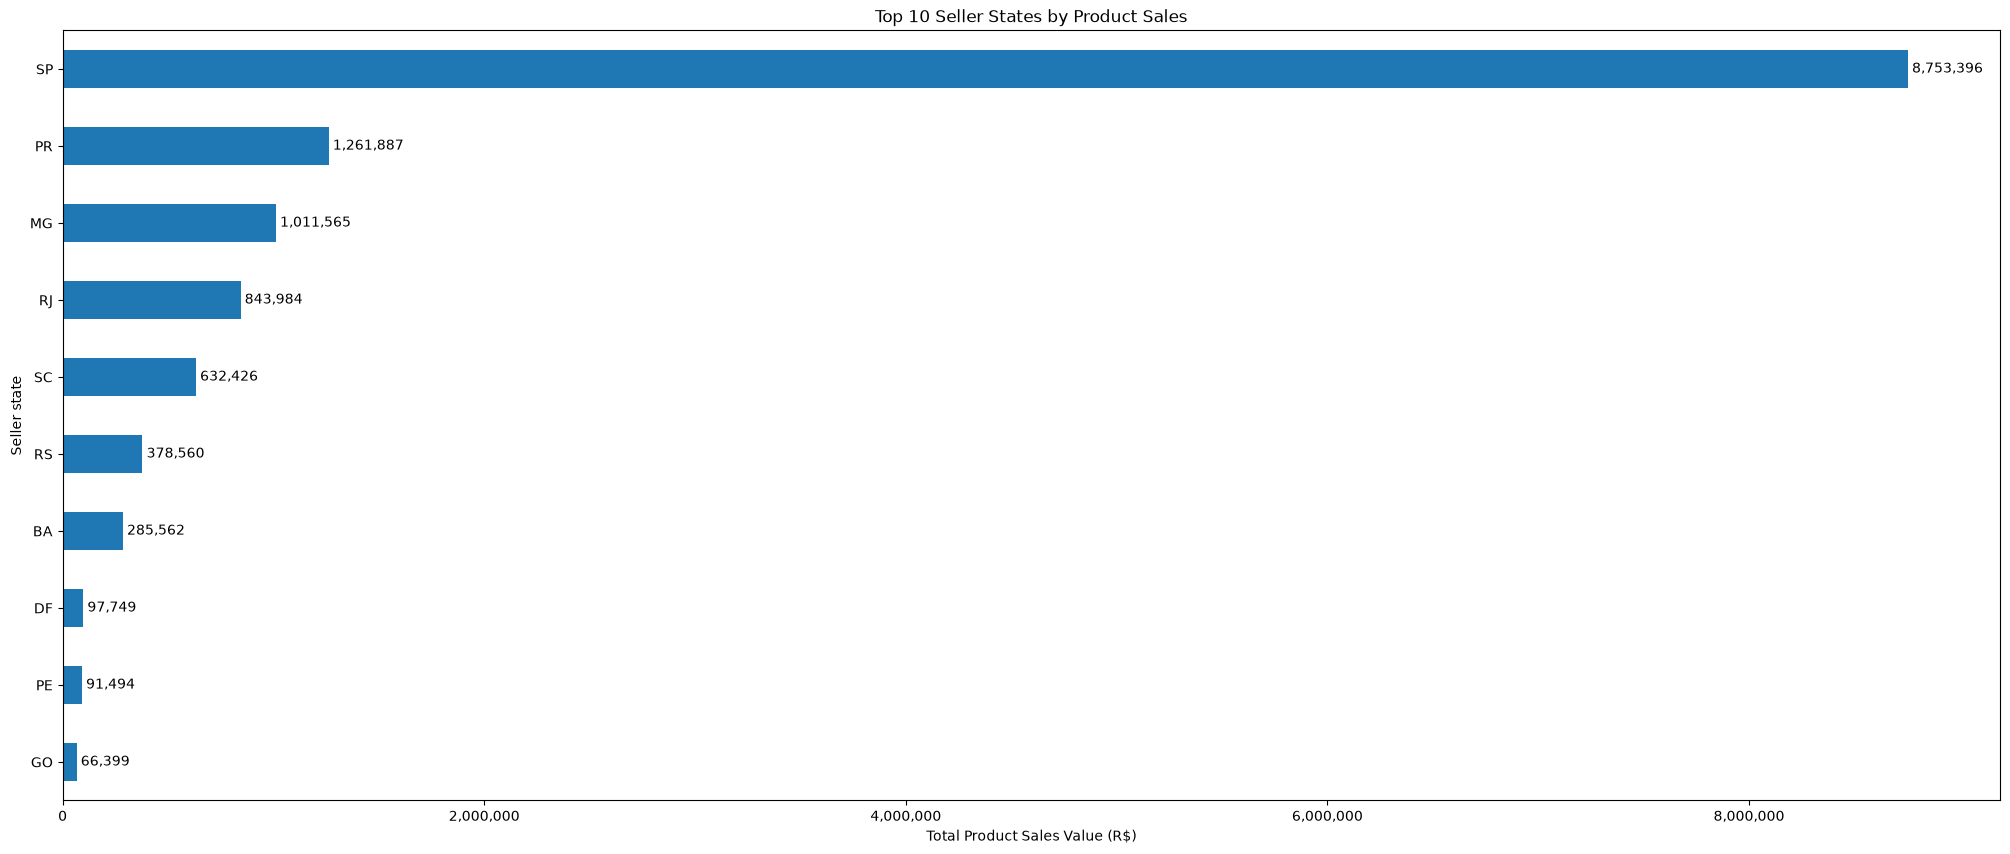

In [1209]:
sales_by_state.head(10).plot(kind="barh",figsize=(25,10))
plt.title("Top 10 Seller States by Product Sales")
plt.xlabel("Total Product Sales Value (R$)")
plt.ylabel("Seller state")
plt.ticklabel_format(axis="x",style="plain")
plt.bar_label(plt.gca().containers[0], fmt='{:,.0f}', padding=3)
from matplotlib.ticker import StrMethodFormatter

plt.gca().xaxis.set_major_formatter(StrMethodFormatter('{x:,.0f}'))
plt.gca().invert_yaxis()

### Seller State Performance by Product Sales

São Paulo (SP) recorded the highest product sales at R$8.75 million, followed by Paraná (PR) at R$1.26 million and Minas Gerais (MG) at R$1.01 million. São Paulo significantly dominates product sales compared with other seller states.

In [1210]:
sales_percentage_by_state=sales_by_state/sales_by_state.sum()*100

In [1211]:
sales_percentage_by_state

seller_state
SP    64.402779
PR     9.284287
MG     7.442549
RJ     6.209582
SC     4.653051
RS     2.785237
BA     2.101008
DF     0.719188
PE     0.673163
GO     0.488530
ES     0.350874
MA     0.267877
CE     0.148920
PB     0.125776
MT     0.125597
RN     0.073520
MS     0.062919
RO     0.035038
PI     0.018556
SE     0.011818
PA     0.009109
AM     0.008660
AC     0.001964
Name: price, dtype: float64

### Seller State Contribution to Total Product Sales

São Paulo (SP) contributes 64.40% of total product sales, followed by Paraná (PR) at 9.28% and Minas Gerais (MG) at 7.44%. The top three states account for approximately 81.13% of total product sales, indicating a strong geographical concentration of seller activity.

In [1212]:
(orders["order_delivered_customer_date"]-orders["order_purchase_timestamp"]).head(10)

0    8 days 10:28:40
1   13 days 18:46:08
2    9 days 09:27:40
3   13 days 05:00:36
4    2 days 20:58:23
5   16 days 13:00:50
6                NaT
7    9 days 23:45:21
8    9 days 19:39:01
9   18 days 05:19:28
dtype: timedelta64[us]

In [1213]:
actual_delivery_days=(orders["order_delivered_customer_date"]-orders["order_purchase_timestamp"]).dt.total_seconds()/86400

In [1214]:
actual_delivery_days.head(10)

0     8.436574
1    13.782037
2     9.394213
3    13.208750
4     2.873877
5    16.542245
6          NaN
7     9.989826
8     9.818762
9    18.221852
dtype: float64

In [1215]:

actual_delivery_days.describe()


count    96476.000000
mean        12.558702
std          9.546530
min          0.533414
25%          6.766403
50%         10.217755
75%         15.720327
max        209.628611
dtype: float64

In [1216]:
(actual_delivery_days > 60).sum()

np.int64(306)

In [1217]:
(actual_delivery_days > 60).mean() * 100

np.float64(0.3077201556701964)

In [1218]:
orders[["order_id","order_status","order_purchase_timestamp","order_delivered_customer_date","order_estimated_delivery_date"]][(actual_delivery_days > 60)]

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
252,f31535f21d145b2345e2bf7f09d62322,delivered,2018-02-01 07:47:34,2018-04-23 15:49:34,2018-03-05
658,cafc9b2f7d35ec42bdb74347cc6e8a70,delivered,2018-01-19 00:48:30,2018-04-04 17:12:36,2018-02-16
1536,b5195225c11fc325d686d24fe14eedbb,delivered,2018-03-02 10:35:38,2018-05-07 15:59:16,2018-04-04
1563,56af0400ccac703cca01cd9846d29c58,delivered,2018-02-20 17:37:20,2018-05-06 17:08:31,2018-03-19
1621,a4efaffc506a395c9cea7402b078c1e5,delivered,2018-01-17 10:50:09,2018-05-07 19:25:33,2018-02-23
...,...,...,...,...,...
97290,5687858ec96eba8c66c04d8a08ff4e42,delivered,2018-02-25 11:24:39,2018-05-03 00:48:41,2018-03-21
97899,443038d9ed6b74bc4f7bfa679ce81bf1,delivered,2018-02-24 21:26:42,2018-05-07 22:31:53,2018-04-05
97961,16efc11ccab2e8a17656020f80cd39e3,delivered,2017-12-01 16:13:44,2018-02-05 21:08:10,2017-12-27
98227,2e56f943f231f5fe108f43fb370b0ed6,delivered,2017-02-09 12:12:22,2017-05-25 07:14:44,2017-03-16


In [1219]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence', 'order_month'],
      dtype='str')

In [1220]:
order_delivery_days_delay=(orders["order_delivered_customer_date"]-orders["order_estimated_delivery_date"]).dt.total_seconds() / 86400 

In [1221]:
order_delivery_days_delay.head()

0    -7.107488
1    -5.355729
2   -17.245498
3   -12.980069
4    -9.238171
dtype: float64

In [1222]:
order_delivery_days_delay.describe()

count    96476.000000
mean       -11.179120
std         10.186113
min       -146.016123
25%        -16.244384
50%        -11.948941
75%         -6.390000
max        188.975081
dtype: float64

In [1223]:
early=(order_delivery_days_delay<0).sum()
on_time=(order_delivery_days_delay==0).sum()
late=(order_delivery_days_delay>0).sum()

print("Early:",early)
print("on Time:",on_time)
print("late:",late)

Early: 88649
on Time: 0
late: 7827


In [1224]:
total=order_delivery_days_delay.notna().sum()
print("Early %:", early / total * 100)
print("On-time %:", on_time / total * 100)
print("Late %:", late / total * 100)

Early %: 91.88710145528421
On-time %: 0.0
Late %: 8.112898544715783



### Delivery Performance Analysis

**Delivery Status Distribution**

Out of 96,476 delivered orders:

| Delivery Status | Number of Orders | Percentage |
|---|---:|---:|
| Delivered Early | 88,649 | 91.89% |
| Delivered On Time | 0 | 0.00% |
| Delivered Late | 7,827 | 8.11% |
| **Total** | **96,476** | **100%** |

**Key Findings:**
- 91.89% of orders were delivered before their estimated delivery dates.
- 8.11% of orders were delivered after their estimated delivery dates.
- No orders matched the estimated delivery timestamp exactly.
- The average delivery delay across all delivered orders was -11.18 days, indicating that orders arrived approximately 11 days earlier than estimated on average.

**Conclusion:**

Olist demonstrated strong delivery performance, with the majority of orders arriving earlier than their estimated delivery dates. However, 7,827 orders experienced delivery delays, indicating opportunities to improve delivery reliability and logistics management.

**Note:** On-time delivery was calculated using exact timestamp equality. A practical definition could allow a tolerance around the estimated delivery date.


In [1225]:
late_deliveries=order_delivery_days_delay[order_delivery_days_delay>0]

In [1226]:
late_deliveries.describe()

count    7827.000000
mean        9.552206
std        13.951700
min         0.002500
25%         1.867193
50%         5.807894
75%        11.822471
max       188.975081
dtype: float64


### Analysis of Late Deliveries

A total of 7,827 orders (8.11% of delivered orders) arrived after their estimated delivery dates.

**Delivery Delay Statistics:**
- Average delay: 9.55 days.
- Median delay: 5.81 days.
- Minimum delay: 0.0025 days (approximately 3.6 minutes).
- Maximum delay: 188.98 days.
- 75% of late orders experienced delays of up to 11.82 days.

**Key Findings:**
- Most late orders experienced relatively short delays.
- The average delay is higher than the median, indicating the presence of extreme delivery delays.
- A small number of orders experienced exceptionally long delays.

**Conclusion:**

Although most Olist orders were delivered earlier than estimated, late orders experienced an average delay of approximately 9.55 days. Improving logistics and investigating extreme delivery delays could help improve customer satisfaction.


Text(0.5, 1.0, 'Distribution of Late Delivery Days')

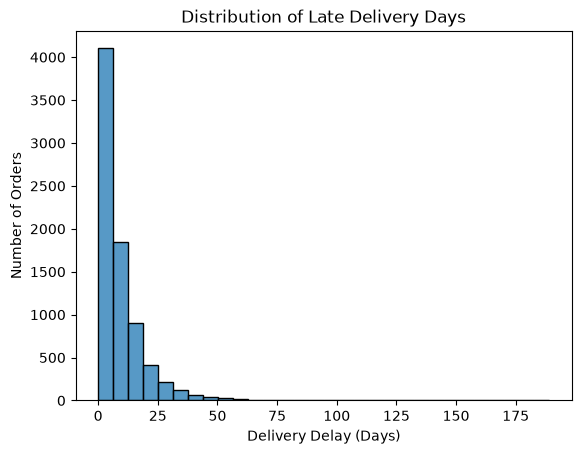

In [1227]:
sns.histplot(x=late_deliveries,bins=30)
plt.xlabel("Delivery Delay (Days)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Late Delivery Days")

In [1228]:
(late_deliveries>30).sum()

np.int64(360)

In [1229]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence', 'order_month'],
      dtype='str')

In [1230]:
severe_delays = orders.loc[
    late_deliveries[late_deliveries > 30].index,
    ["order_id", "order_status",
     "order_purchase_timestamp",
     "order_delivered_customer_date",
     "order_estimated_delivery_date",
     ]
]

In [1231]:
severe_delays.head(10)

,order_id,order_status,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date
110,9d531c565e28c3e0d756192f84d8731f,delivered,2017-11-28 21:00:44,2018-01-23 21:38:52,2017-12-22
115,8fc207e94fa91a7649c5a5dab690272a,delivered,2017-11-26 17:49:46,2018-01-20 13:42:22,2017-12-19
252,f31535f21d145b2345e2bf7f09d62322,delivered,2018-02-01 07:47:34,2018-04-23 15:49:34,2018-03-05
445,690199d6a2c51ff57c6b392d7680cbfd,delivered,2018-03-16 11:31:18,2018-05-14 12:28:56,2018-04-11
658,cafc9b2f7d35ec42bdb74347cc6e8a70,delivered,2018-01-19 00:48:30,2018-04-04 17:12:36,2018-02-16
1241,81f2ee7669eee05b13906d24d43ebc69,delivered,2018-04-03 09:40:44,2018-06-01 19:56:25,2018-04-13
1536,b5195225c11fc325d686d24fe14eedbb,delivered,2018-03-02 10:35:38,2018-05-07 15:59:16,2018-04-04
1563,56af0400ccac703cca01cd9846d29c58,delivered,2018-02-20 17:37:20,2018-05-06 17:08:31,2018-03-19
1567,790512cc033ced5f8fe1f9158eb8f2fe,delivered,2018-02-28 22:34:44,2018-04-21 20:14:29,2018-03-20
1621,a4efaffc506a395c9cea7402b078c1e5,delivered,2018-01-17 10:50:09,2018-05-07 19:25:33,2018-02-23



### Investigation of Severe Delivery Delays

- Identified 360 orders with delivery delays exceeding 30 days.
- These represent approximately 4.60% of all late deliveries.
- The inspected records show actual delivery dates significantly later than estimated delivery dates.
- All inspected orders have a delivered status.
- These delays appear to be genuine delivery-performance issues rather than obvious date-format errors.

**Conclusion:**

A small proportion of orders experienced severe delivery delays. These orders should be retained in the dataset because they represent actual delivery performance and may provide useful insights for logistics analysis.


In [1232]:
orders["purchase_to_approval_hours"] = (
    orders["order_approved_at"] -
    orders["order_purchase_timestamp"]
).dt.total_seconds() / 3600

In [1233]:
orders["purchase_to_approval_hours"].describe()

count    99281.000000
mean        10.419094
std         26.038004
min          0.000000
25%          0.215000
50%          0.343333
75%         14.580833
max       4509.180556
Name: purchase_to_approval_hours, dtype: float64


### Purchase to Approval Analysis

**Key Findings:**
- Average approval time was approximately 10.42 hours.
- Median approval time was approximately 20.6 minutes.
- 25% of orders were approved within approximately 13 minutes.
- The maximum approval time was approximately 188 days.
- The mean is considerably higher than the median, indicating extreme values in approval duration.

**Conclusion:**

Most orders were approved relatively quickly, as indicated by the median approval time. However, a small number of orders experienced unusually long approval durations, which increased the overall average.


In [1234]:
(orders["purchase_to_approval_hours"] > 24).sum()

np.int64(17419)


**Approval Time Analysis:**
- 17,419 orders (17.54%) took more than 24 hours for approval.
- 81,862 orders (82.46%) were approved within 24 hours.
- Although the median approval time was approximately 20.6 minutes, a considerable number of orders experienced approval delays.

**Conclusion:**

Most orders were approved within 24 hours. However, approximately 17.54% took longer, indicating potential delays in the order approval process.


In [1235]:
orders[["order_id", "order_status",
     "order_purchase_timestamp","order_approved_at",
     "order_delivered_customer_date",
     "order_estimated_delivery_date",
     ]][orders["purchase_to_approval_hours"]>24].head(10)

,order_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_customer_date,order_estimated_delivery_date
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-08-07 15:27:45,2018-08-13
6,136cce7faa42fdb2cefd53fdc79a6098,invoiced,2017-04-11 12:22:08,2017-04-13 13:25:17,NaT,2017-05-09
8,76c6e866289321a7c93b82b54852dc33,delivered,2017-01-23 18:29:09,2017-01-25 02:50:47,2017-02-02 14:08:10,2017-03-06
12,82566a660a982b15fb86e904c8d32918,delivered,2018-06-07 10:06:19,2018-06-09 03:13:12,2018-06-19 12:05:52,2018-07-18
15,dcb36b511fcac050b97cd5c05de84dc3,delivered,2018-06-07 19:03:12,2018-06-12 23:31:02,2018-06-21 15:34:32,2018-07-04
25,fbf9ac61453ac646ce8ad9783d7d0af6,delivered,2018-02-20 23:46:53,2018-02-22 02:30:46,2018-03-21 22:03:54,2018-03-12
26,acce194856392f074dbf9dada14d8d82,delivered,2018-06-04 00:00:13,2018-06-05 00:35:10,2018-06-16 15:20:55,2018-07-18
28,91b2a010e1e45e6ba3d133fa997597be,delivered,2018-05-02 11:45:38,2018-05-03 12:55:01,2018-05-16 20:56:24,2018-05-23
30,f70a0aff17df5a6cdd9a7196128bd354,delivered,2017-08-10 11:58:33,2017-08-12 02:45:24,2017-08-18 14:28:02,2017-08-23
32,989225ba6d0ebd5873335f7e01de2ae7,delivered,2017-12-12 13:56:04,2017-12-14 13:54:13,2018-01-03 18:03:36,2018-01-08


In [1236]:
(orders["purchase_to_approval_hours"] > 48).sum()

np.int64(5166)


**Approval Delay Analysis:**

- 17,419 orders (17.54%) took more than 24 hours for approval.
- 5,166 orders (5.20%) took more than 48 hours for approval.
- 81,862 orders (82.46%) were approved within 24 hours.

**Key Finding:**

Although most orders were approved within 24 hours, 5,166 orders experienced approval delays exceeding two days.

**Conclusion:**

The order approval process was relatively quick for most orders. However, longer approval times for a smaller proportion of orders indicate opportunities to improve approval efficiency.


Text(0.5, 1.0, 'Distribution of Purchase to Approval Time (Within 48 Hours)')

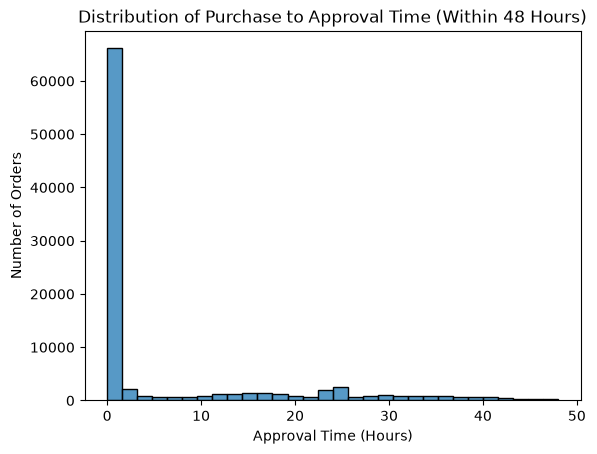

In [1237]:

sns.histplot(
    x=orders.loc[
        orders["purchase_to_approval_hours"] <= 48,
        "purchase_to_approval_hours"
    ],
    bins=30
)

plt.xlabel("Approval Time (Hours)")
plt.ylabel("Number of Orders")
plt.title("Distribution of Purchase to Approval Time (Within 48 Hours)")



**Purchase-to-Approval Time Distribution:**

- Most orders were approved shortly after purchase.
- The distribution is strongly right-skewed, indicating that a smaller proportion of orders experienced longer approval times.
- Some orders took between 10 and 48 hours for approval.
- The median approval time was approximately 20.6 minutes.

**Conclusion:**

The majority of orders were approved quickly. However, a smaller proportion experienced substantial approval delays, highlighting an opportunity to improve the order approval process.

**Note:** The histogram displays only orders with approval times of 48 hours or less. Extreme approval delays are retained in the dataset.


In [1238]:
orders["approval_to_carrier_hours"]=((orders["order_delivered_carrier_date"]-orders["order_approved_at"]).dt.total_seconds())/3600

In [1239]:
orders["approval_to_carrier_hours"].head(10)

0     56.795833
1     11.109167
2      4.910278
3     89.900000
4     21.434722
5     40.797500
6           NaN
7    140.759722
8     35.428889
9    295.664444
Name: approval_to_carrier_hours, dtype: float64

In [1240]:
orders["approval_to_carrier_hours"].describe()

count    97644.000000
mean        67.320916
std         85.186249
min      -4109.256111
25%         21.012222
50%         43.641528
75%         85.931250
max       3018.301667
Name: approval_to_carrier_hours, dtype: float64

In [1241]:
(orders["approval_to_carrier_hours"]<0).sum()

np.int64(1359)

In [1242]:
approval_to_carrier_less_zero=orders.loc[
    orders["approval_to_carrier_hours"] < 0,
    [
        "order_id",
        "order_status",
        "order_approved_at",
        "order_delivered_carrier_date",
        "approval_to_carrier_hours"
    ]
]

In [1243]:
approval_to_carrier_less_zero["approval_month"] = (
    approval_to_carrier_less_zero["order_approved_at"].dt.to_period("M")
)

In [1244]:
approval_to_carrier_less_zero

,order_id,order_status,order_approved_at,order_delivered_carrier_date,approval_to_carrier_hours,approval_month
15,dcb36b511fcac050b97cd5c05de84dc3,delivered,2018-06-12 23:31:02,2018-06-11 14:54:00,-32.617222,2018-06
64,688052146432ef8253587b930b01a06d,delivered,2018-04-24 18:25:22,2018-04-23 19:19:14,-23.102222,2018-04
199,58d4c4747ee059eeeb865b349b41f53a,delivered,2018-07-26 23:31:53,2018-07-24 12:57:00,-58.581389,2018-07
210,412fccb2b44a99b36714bca3fef8ad7b,delivered,2018-07-23 12:31:53,2018-07-23 12:24:00,-0.131389,2018-07
415,56a4ac10a4a8f2ba7693523bb439eede,delivered,2018-07-27 23:31:09,2018-07-24 14:03:00,-81.469167,2018-07
...,...,...,...,...,...,...
99091,240ead1a7284667e0ec71d01f80e4d5e,delivered,2018-07-05 16:17:59,2018-07-05 14:11:00,-2.116389,2018-07
99230,78008d03bd8ef7fcf1568728b316553c,delivered,2018-07-05 16:32:52,2018-07-03 12:57:00,-51.597778,2018-07
99266,76a948cd55bf22799753720d4545dd2d,delivered,2018-02-04 23:31:46,2018-01-31 18:11:58,-101.330000,2018-02
99377,a6bd1f93b7ff72cc348ca07f38ec4bee,delivered,2018-04-24 19:26:10,2018-04-23 17:18:40,-26.125000,2018-04


In [1245]:
negative_by_month = (
    approval_to_carrier_less_zero
    .groupby("approval_month")["order_id"]
    .count()
    .sort_index()
)

In [1246]:
negative_by_month

approval_month
2017-03      1
2017-04     24
2017-05     14
2017-06      2
2017-07      3
2017-08     21
2017-09     13
2017-12      6
2018-01      1
2018-02     36
2018-03      2
2018-04    393
2018-05     68
2018-06     95
2018-07    565
2018-08    115
Freq: M, Name: order_id, dtype: int64

In [1247]:
approval_to_carrier_less_zero[approval_to_carrier_less_zero["approval_to_carrier_hours"]<-48].head(10)

,order_id,order_status,order_approved_at,order_delivered_carrier_date,approval_to_carrier_hours,approval_month
199,58d4c4747ee059eeeb865b349b41f53a,delivered,2018-07-26 23:31:53,2018-07-24 12:57:00,-58.581389,2018-07
415,56a4ac10a4a8f2ba7693523bb439eede,delivered,2018-07-27 23:31:09,2018-07-24 14:03:00,-81.469167,2018-07
483,4df92d82d79c3b52c7138679fa9b07fc,delivered,2018-07-29 23:30:52,2018-07-26 14:46:00,-80.747778,2018-07
1214,0fe8aad910ff05e73b0ddb0a89e61b21,delivered,2018-07-05 16:02:47,2018-07-03 10:21:00,-53.696389,2018-07
1905,f384f4edb05c390598d9010ea97f7f4e,delivered,2018-04-24 18:39:10,2018-04-21 01:32:06,-89.117778,2018-04
1986,6e57e23ecac1ae881286657694444267,delivered,2018-08-20 15:55:42,2018-08-14 13:26:00,-146.495000,2018-08
2625,7cb67275a494651008ed5b1f0353ddce,delivered,2018-07-05 16:27:53,2018-07-03 10:18:00,-54.164722,2018-07
2945,846de1a3e7ca6bf29333e1db02040ab6,delivered,2018-02-04 23:31:38,2018-01-31 19:48:36,-99.717222,2018-02
3470,3505a2f5fdc9c1c19d2eea9bfdac56c4,delivered,2018-07-13 16:06:19,2018-07-11 14:23:00,-49.721944,2018-07
3659,f222c56f035b47dfa1e069a88235d730,delivered,2018-02-04 23:31:47,2018-01-31 19:48:44,-99.717500,2018-02



### Investigation of Negative Approval-to-Carrier Durations

- Identified 1,359 orders with negative approval-to-carrier durations.
- 178 records (13.10%) had negative durations exceeding 48 hours.
- The issue was concentrated particularly in April and July 2018.
- The inspected records had delivered status and carrier handover timestamps earlier than approval timestamps.
- These records indicate chronological inconsistencies in the recorded timestamps.

**Conclusion:**

Negative approval-to-carrier durations represent timestamp inconsistencies that should be flagged during data validation. The original timestamps should be retained rather than arbitrarily modified or deleted.


In [1248]:
orders[orders["approval_to_carrier_hours"]>48]["approval_to_carrier_hours"].describe()

count    45085.000000
mean       119.873772
std         99.755169
min         48.000556
25%         67.175000
50%         90.993889
75%        135.315000
max       3018.301667
Name: approval_to_carrier_hours, dtype: float64

In [1249]:
orders[orders["approval_to_carrier_hours"]>48].head(10)

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date,delivered_without_approval,invalid_approval_carrier_sequence,invalid_carrier_customer_sequence,order_month,purchase_to_approval_hours,approval_to_carrier_hours
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,False,False,False,False,2017-10,0.178333,56.795833
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,False,False,False,False,2017-11,0.298056,89.900000
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,2017-05-16 13:10:30,2017-05-16 13:22:11,2017-05-22 10:07:46,2017-05-26 12:55:51,2017-06-07,False,False,False,False,False,2017-05,0.194722,140.759722
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,2017-07-29 11:55:02,2017-07-29 12:05:32,2017-08-10 19:45:24,2017-08-16 17:14:30,2017-08-23,False,False,False,False,False,2017-07,0.175000,295.664444
12,82566a660a982b15fb86e904c8d32918,d3e3b74c766bc6214e0c830b17ee2341,delivered,2018-06-07 10:06:19,2018-06-09 03:13:12,2018-06-11 13:29:00,2018-06-19 12:05:52,2018-07-18,False,False,False,False,False,2018-06,41.114722,58.263333
18,85ce859fd6dc634de8d2f1e290444043,059f7fc5719c7da6cbafe370971a8d70,delivered,2017-11-21 00:03:41,2017-11-21 00:14:22,2017-11-23 21:32:26,2017-11-27 18:28:00,2017-12-11,False,False,False,False,False,2017-11,0.178056,69.301111
20,203096f03d82e0dffbc41ebc2e2bcfb7,d2b091571da224a1b36412c18bc3bbfe,delivered,2017-09-18 14:31:30,2017-09-19 04:04:09,2017-10-06 17:50:03,2017-10-09 22:23:46,2017-09-28,True,False,False,False,False,2017-09,13.544167,421.765000
22,2807d0e504d6d4894d41672727bc139f,72ae281627a6102d9b3718528b420f8a,delivered,2018-02-03 20:37:35,2018-02-03 20:50:22,2018-02-05 22:37:28,2018-02-08 16:13:46,2018-02-21,False,False,False,False,False,2018-02,0.213056,49.785000
23,95266dbfb7e20354baba07964dac78d5,a166da34890074091a942054b36e4265,delivered,2018-01-08 07:55:29,2018-01-08 08:07:31,2018-01-24 23:16:37,2018-01-26 17:32:38,2018-02-21,False,False,False,False,False,2018-01,0.200556,399.151667
25,fbf9ac61453ac646ce8ad9783d7d0af6,3a874b4d4c4b6543206ff5d89287f0c3,delivered,2018-02-20 23:46:53,2018-02-22 02:30:46,2018-02-26 22:25:22,2018-03-21 22:03:54,2018-03-12,False,False,False,False,False,2018-02,26.731389,115.910000


In [1250]:
orders[orders["approval_to_carrier_hours"]>48]["approval_to_carrier_hours"].describe()

count    45085.000000
mean       119.873772
std         99.755169
min         48.000556
25%         67.175000
50%         90.993889
75%        135.315000
max       3018.301667
Name: approval_to_carrier_hours, dtype: float64

Text(0, 0.5, 'Number of orders')

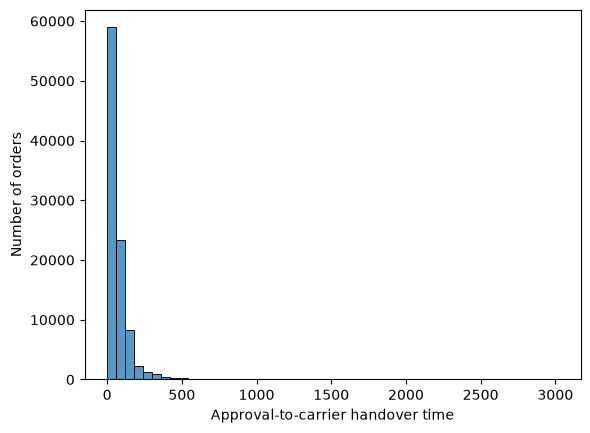

In [1251]:
sns.histplot(x=orders[orders["approval_to_carrier_hours"]>0]["approval_to_carrier_hours"],bins=50)
plt.title("")
plt.xlabel("Approval-to-carrier handover time")
plt.ylabel("Number of orders")

Text(0, 0.5, 'Number of orders')

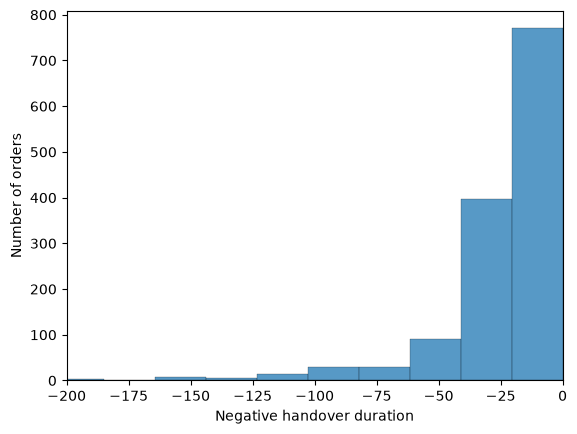

In [1252]:
sns.histplot(x=orders[orders["approval_to_carrier_hours"]<0]["approval_to_carrier_hours"],bins=200)
plt.xlim(-200,0)
plt.xlabel("Negative handover duration")
plt.ylabel("Number of orders")

### Approval-to-Carrier Handover Analysis

- Analysed the time between order approval and carrier handover.
- Found 1,359 negative durations, indicating invalid timestamp sequences. These records were flagged and retained without modification.
- Valid records: 96,285.
- Average handover time: 68.62 hours.
- Median handover time: 44.44 hours.
- 45,085 orders (46.82%) took more than 48 hours for carrier handover.
- The valid handover-time distribution is right-skewed, with a small number of unusually long durations.
- Used separate histograms to examine valid and negative durations.

In [1253]:
orders["carrier_to_customer_hours"]=(orders["order_delivered_customer_date"]-orders["order_delivered_carrier_date"]).dt.total_seconds()/3600

In [1254]:
orders["carrier_to_customer_hours"].describe()

count    96475.000000
mean       223.933126
std        210.242923
min       -386.308056
25%         98.398750
50%        170.394444
75%        288.698750
max       4924.583333
Name: carrier_to_customer_hours, dtype: float64

In [1255]:
orders[orders["carrier_to_customer_hours"]<0]["carrier_to_customer_hours"].describe()

count     23.000000
mean     -78.455133
std       89.308070
min     -386.308056
25%     -128.759028
50%      -39.864444
75%      -23.338333
max       -0.388333
Name: carrier_to_customer_hours, dtype: float64

In [1256]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence', 'order_month',
       'purchase_to_approval_hours', 'approval_to_carrier_hours',
       'carrier_to_customer_hours'],
      dtype='str')

In [1257]:
orders["invalid_delivery_date"].value_counts()

invalid_delivery_date
False    98968
True       473
Name: count, dtype: int64

In [1258]:
orders[orders["carrier_to_customer_hours"]<0]

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,invalid_delivery_date,canceled_with_delivery_date,delivered_without_approval,invalid_approval_carrier_sequence,invalid_carrier_customer_sequence,order_month,purchase_to_approval_hours,approval_to_carrier_hours,carrier_to_customer_hours
6437,a1abeb653a4d4cd1e142ccb8c82cd069,5f50465da00b7fed5dd1239f4ecf6e2c,delivered,2017-07-20 11:20:52,2017-07-21 06:43:14,2017-07-28 16:57:58,2017-07-25 19:32:56,2017-08-14,False,False,False,False,True,2017-07,19.372778,178.245556,-69.417222
9553,383aa8b2724fe452d9ccd9934a8c628b,b1cb2f9d7a19480f3749e248db14d58f,delivered,2017-07-02 20:58:43,2017-07-02 21:10:20,2017-07-07 17:22:41,2017-07-06 14:27:51,2017-07-21,False,False,False,False,True,2017-07,0.193611,116.205833,-26.913889
13487,cb1134f9010d242e9515ad1c78ec0c39,2fd33ac77677bd214b1882868317eeed,delivered,2017-07-16 12:35:34,2017-07-18 06:03:50,2017-07-20 19:22:02,2017-07-19 14:13:28,2017-08-08,False,False,False,False,True,2017-07,41.471111,61.303333,-29.142778
14474,dceb62e8fa94b46006c9554fed743df0,2721900eb4e0f1cc2c836dd7bc1b1e11,delivered,2017-07-20 20:58:05,2017-07-22 11:45:11,2017-08-01 18:23:30,2017-07-26 18:09:10,2017-08-11,False,False,False,False,True,2017-07,38.785000,246.638611,-144.238889
19268,5f9d46795c3126674e52becb3a1a517f,79287bcaafdde5c793b996fc40bb7d9f,delivered,2017-07-18 11:48:20,2017-07-18 12:03:29,2017-07-20 23:03:42,2017-07-20 18:52:41,2017-07-31,False,False,False,False,True,2017-07,0.252500,59.003611,-4.183611
21338,8c78d01de3a9009e23d6877a7cc9be20,6cd7106899e59a1fbd0622d5f1efedf4,delivered,2016-10-08 15:36:50,2016-10-08 18:13:44,2016-10-26 11:41:53,2016-10-25 17:51:46,2016-11-30,False,False,False,False,True,2016-10,2.615000,425.469167,-17.835278
22520,b27af682321527a6349f1761eb3f360c,9859dd92e872dbaa60ca3cd5f0d7ad07,delivered,2017-06-14 20:17:04,2017-06-14 20:30:08,2017-06-27 14:51:54,2017-06-26 15:45:35,2017-07-14,False,False,False,False,True,2017-06,0.217778,306.362778,-23.105278
25393,1cc3ae63caffff2d6c3ee3e78e074acf,01c843a2c0600def0b7693dba47af460,delivered,2017-08-07 21:35:22,2017-08-08 21:45:15,2017-08-10 18:28:56,2017-08-10 18:05:38,2017-08-25,False,False,False,False,True,2017-08,24.164722,44.728056,-0.388333
25646,e37f11cae9985ca58f0b56f268720537,3947a361301f2ff0f3223159a0f2701c,delivered,2017-07-26 11:46:34,2017-07-27 10:10:16,2017-08-01 18:17:47,2017-07-31 17:49:56,2017-08-24,False,False,False,False,True,2017-07,22.395000,128.125278,-24.464167
27470,fa3e37584f4fdb1ded0e0de700dfcb4e,63be4feff10a0b1d85f2cfbf10df9754,delivered,2017-07-30 19:32:23,2017-07-30 19:45:09,2017-08-09 18:18:43,2017-08-01 21:13:01,2017-08-18,False,False,False,False,True,2017-07,0.212778,238.559444,-189.095000


In [1259]:
orders["delivered_without_approval"].value_counts()

delivered_without_approval
False    99427
True        14
Name: count, dtype: int64

In [1260]:
orders["invalid_carrier_customer_sequence"].value_counts()

invalid_carrier_customer_sequence
False    99418
True        23
Name: count, dtype: int64

In [1261]:
orders[orders["carrier_to_customer_hours"]>=0]["carrier_to_customer_hours"].describe()

count    96452.000000
mean       224.005234
std        210.211793
min          0.000000
25%         98.436597
50%        170.407500
75%        288.730625
max       4924.583333
Name: carrier_to_customer_hours, dtype: float64

In [1262]:
orders[orders["carrier_to_customer_hours"]>168]["carrier_to_customer_hours"].describe()

count    50073.000000
mean       344.920176
std        229.589849
min        168.001111
25%        206.790833
50%        284.423889
75%        392.749444
max       4924.583333
Name: carrier_to_customer_hours, dtype: float64

Text(0, 0.5, 'Number of orders')

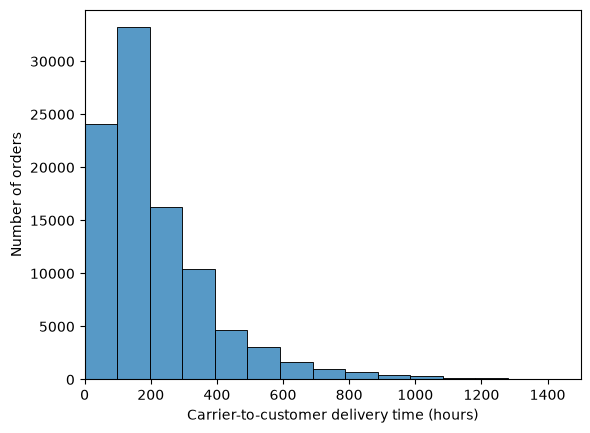

In [1263]:
sns.histplot(x=orders[orders["carrier_to_customer_hours"]>=0]["carrier_to_customer_hours"],bins=50)
plt.xlim(0,1500)
plt.xlabel("Carrier-to-customer delivery time (hours)")
plt.ylabel("Number of orders")

In [1264]:
order_month_avg_delivery_hours=orders.groupby("order_month")["carrier_to_customer_hours"].mean()

In [1265]:
orders.groupby("order_month")["carrier_to_customer_hours"].count()

order_month
2016-09       1
2016-10     270
2016-12       1
2017-01     750
2017-02    1653
2017-03    2546
2017-04    2303
2017-05    3545
2017-06    3135
2017-07    3872
2017-08    4193
2017-09    4149
2017-10    4478
2017-11    7288
2017-12    5513
2018-01    7069
2018-02    6556
2018-03    7003
2018-04    6798
2018-05    6749
2018-06    6096
2018-07    6156
2018-08    6351
2018-09       0
2018-10       0
Freq: M, Name: carrier_to_customer_hours, dtype: int64

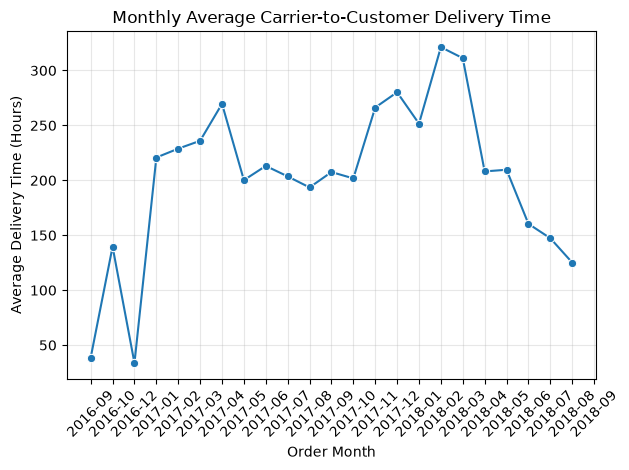

In [1266]:
sns.lineplot(x=order_month_avg_delivery_hours.index.astype(str),y=order_month_avg_delivery_hours,marker="o")
plt.title("Monthly Average Carrier-to-Customer Delivery Time")
plt.xlabel("Order Month")
plt.ylabel("Average Delivery Time (Hours)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Monthly Carrier-to-Customer Delivery Analysis

- Analysed monthly average delivery time from carrier handover to customer delivery.
- Excluded 23 records with invalid negative durations.
- Delivery time reached its highest average in February 2018 at 321.26 hours (13.39 days).
- A decreasing trend was observed from March to August 2018.
- August 2018 recorded an average delivery time of 125.15 hours (5.21 days).
- Monthly delivery performance fluctuated considerably throughout the observed period.
- Months with very few valid records were treated cautiously.

In [1267]:
order_items["freight_value"].describe()

count    112650.000000
mean         19.990320
std          15.806405
min           0.000000
25%          13.080000
50%          16.260000
75%          21.150000
max         409.680000
Name: freight_value, dtype: float64

In [1268]:
order_items.columns

Index(['order_id', 'order_item_id', 'product_id', 'seller_id',
       'shipping_limit_date', 'price', 'freight_value'],
      dtype='str')

<Axes: xlabel='freight_value', ylabel='Count'>

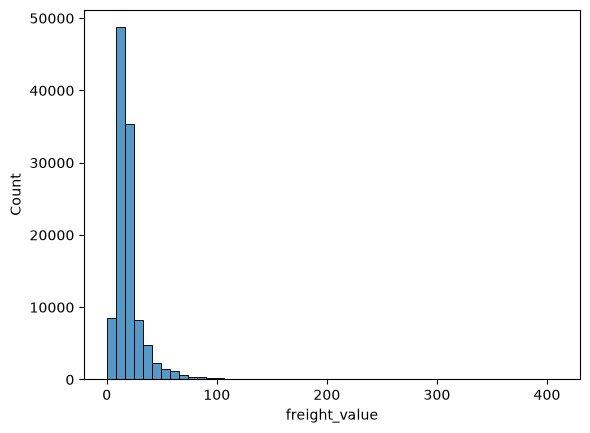

In [1269]:
sns.histplot(x=order_items["freight_value"],bins=50)


In [1270]:
order_items[order_items["freight_value"]==0].count()

order_id               383
order_item_id          383
product_id             383
seller_id              383
shipping_limit_date    383
price                  383
freight_value          383
dtype: int64

In [1271]:
freight_analysis=order_items[["order_id","product_id","freight_value","price"]].merge(products[["product_id","product_category_name"]],on="product_id")

In [1272]:
freight_analysis.shape

(112650, 5)

In [1273]:
freight_analysis.head()

,order_id,product_id,freight_value,price,product_category_name
0,00010242fe8c5a6d1ba2dd792cb16214,4244733e06e7ecb4970a6e2683c13e61,13.29,58.90,cool_stuff
1,00018f77f2f0320c557190d7a144bdd3,e5f2d52b802189ee658865ca93d83a8f,19.93,239.90,pet_shop
2,000229ec398224ef6ca0657da4fc703e,c777355d18b72b67abbeef9df44fd0fd,17.87,199.00,moveis_decoracao
3,00024acbcdf0a6daa1e931b038114c75,7634da152a4610f1595efa32f14722fc,12.79,12.99,perfumaria
4,00042b26cf59d7ce69dfabb4e55b4fd9,ac6c3623068f30de03045865e4e10089,18.14,199.90,ferramentas_jardim


In [1274]:
freight_analysis["product_category_name"].isnull().sum()

np.int64(1603)

In [1275]:
freight_analysis=freight_analysis.dropna(subset=["product_category_name"])

In [1276]:
freight_analysis.groupby("product_category_name")["freight_value"].mean().sort_values(ascending=False).head(10)

product_category_name
pcs                                               48.454680
eletrodomesticos_2                                44.538571
moveis_colchao_e_estofado                         42.906842
moveis_cozinha_area_de_servico_jantar_e_jardim    42.702598
moveis_quarto                                     42.497523
moveis_escritorio                                 40.551124
portateis_casa_forno_e_cafe                       36.156053
moveis_sala                                       35.722008
sinalizacao_e_seguranca                           32.702613
industria_comercio_e_negocios                     29.420448
Name: freight_value, dtype: float64

In [1277]:
freight_analysis.groupby("product_category_name")["freight_value"].mean().sort_values().head(10)

product_category_name
fashion_roupa_infanto_juvenil     11.938750
livros_importados                 12.830833
fashion_roupa_feminina            12.953125
casa_conforto_2                   13.677000
alimentos                         14.256922
fashion_underwear_e_moda_praia    14.627405
fraldas_higiene                   14.709744
tablets_impressao_imagem          14.773494
flores                            14.814242
pc_gamer                          14.841111
Name: freight_value, dtype: float64

In [1278]:
freight_analysis.groupby("product_category_name")[["freight_value","price"]].mean()

,freight_value,price
product_category_name,,
agro_industria_e_comercio,27.564151,342.124858
alimentos,14.256922,57.634137
alimentos_bebidas,16.215791,54.602446
artes,19.354880,115.802105
artes_e_artesanato,15.422083,75.583750
...,...,...
sinalizacao_e_seguranca,32.702613,108.086583
tablets_impressao_imagem,14.773494,90.703735
telefonia,15.669041,71.213978


In [1279]:
avg_freight_price_analysis["freight_to_price_ratio"]=(avg_freight_price_analysis["freight_value"]/ avg_freight_price_analysis["price"])*100

In [1280]:
avg_freight_price_analysis.sort_values(by="freight_to_price_ratio").head(10)

,freight_value,price,freight_to_price_ratio
product_category_name,,,
fashion_roupa_feminina,12.953125,58.409167,22.176528
alimentos,14.256922,57.634137,24.736939
bebidas,15.148417,59.178628,25.597783
eletronicos,16.833509,57.913531,29.066626
alimentos_bebidas,16.215791,54.602446,29.697921
cds_dvds_musicais,16.070714,52.142857,30.820548
fraldas_higiene,14.709744,40.194615,36.596304
artigos_de_natal,21.106536,57.521699,36.693172
flores,14.814242,33.637576,44.040755



### Freight Cost Analysis

- Analyzed overall freight cost distribution and identified zero-freight records (383, 0.34%).
- Calculated average freight costs across product categories.
- Compared average product prices with average freight costs.
- Calculated freight-to-price ratios to understand the relative shipping cost burden.

**Key Insights:**
- `pcs` had the highest average freight cost (R$48.45).
- `fashion_roupa_infanto_juvenil` had the lowest average freight cost (R$11.94).
- `casa_conforto_2` had the highest freight-to-price ratio (53.97%).
- `fashion_roupa_feminina` had the lowest ratio (22.18%).
- Lower-priced products can have a relatively higher shipping cost burden.

**Data Handling:** Missing product categories were excluded only from category-level analysis. Zero-freight records were retained.


In [1281]:
orders.columns

Index(['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp',
       'order_approved_at', 'order_delivered_carrier_date',
       'order_delivered_customer_date', 'order_estimated_delivery_date',
       'invalid_delivery_date', 'canceled_with_delivery_date',
       'delivered_without_approval', 'invalid_approval_carrier_sequence',
       'invalid_carrier_customer_sequence', 'order_month',
       'purchase_to_approval_hours', 'approval_to_carrier_hours',
       'carrier_to_customer_hours'],
      dtype='str')

In [1282]:
customers.columns

Index(['customer_id', 'customer_unique_id', 'customer_zip_code_prefix',
       'customer_city', 'customer_state'],
      dtype='str')

In [1283]:
customer_orders = orders[["order_id","customer_id","order_status"]].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

In [1284]:
customer_orders.shape

(99441, 4)

In [1285]:
customer_orders.head(10)

,order_id,customer_id,order_status,customer_unique_id
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,7c396fd4830fd04220f754e42b4e5bff
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,af07308b275d755c9edb36a90c618231
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,3a653a41f6f9fc3d2a113cf8398680e8
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,7c142cf63193a1473d2e66489a9ae977
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,72632f0f9dd73dfee390c9b22eb56dd6
5,a4591c265e18cb1dcee52889e2d8acc3,503740e9ca751ccdda7ba28e9ab8f608,delivered,80bb27c7c16e8f973207a5086ab329e2
6,136cce7faa42fdb2cefd53fdc79a6098,ed0271e0b7da060a393796590e7b737a,invoiced,36edbb3fb164b1f16485364b6fb04c73
7,6514b8ad8028c9f2cc2374ded245783f,9bdf08b4b3b52b5526ff42d37d47f222,delivered,932afa1e708222e5821dac9cd5db4cae
8,76c6e866289321a7c93b82b54852dc33,f54a9f0e6b351c431402b8461ea51999,delivered,39382392765b6dc74812866ee5ee92a7
9,e69bfb5eb88e0ed6a785585b27e16dbf,31ad1d1b63eb9962463f764d4e6e0c9d,delivered,299905e3934e9e181bfb2e164dd4b4f8


In [1286]:
customer_orders["customer_unique_id"].isnull().sum()

np.int64(0)

In [1287]:
customer_orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [1288]:
delivered_customer_orders=customer_orders[customer_orders["order_status"]=="delivered"]

In [1289]:
delivered_customer_orders.groupby("customer_unique_id")["order_id"].count().sort_values(ascending=False).head(10)

customer_unique_id
8d50f5eadf50201ccdcedfb9e2ac8455    15
3e43e6105506432c953e165fb2acf44c     9
6469f99c1f9dfae7733b25662e7f1782     7
1b6c7548a2a1f9037c1fd3ddfed95f33     7
ca77025e7201e3b30c44b472ff346268     7
47c1a3033b8b77b3ab6e109eb4d5fdf3     6
dc813062e0fc23409cd255f7f53c7074     6
63cfc61cee11cbe306bff5857d00bfe4     6
f0e310a6839dce9de1638e0fe5ab282a     6
12f5d6e1cbf93dafd9dcc19095df0b3d     6
Name: order_id, dtype: int64

In [1290]:
orders_per_customer = delivered_customer_orders.groupby(
    "customer_unique_id"
)["order_id"].nunique()

In [1291]:
orders_per_customer.describe()

count    93358.000000
mean         1.033420
std          0.209097
min          1.000000
25%          1.000000
50%          1.000000
75%          1.000000
max         15.000000
Name: order_id, dtype: float64

In [1292]:
(orders_per_customer == 1).sum()

np.int64(90557)

In [1293]:
(orders_per_customer>1).sum()

np.int64(2801)

In [1294]:
(orders_per_customer>1).sum()/orders_per_customer.count()*100

np.float64(3.0002784978255748)

In [1295]:
orders_per_customer.value_counts().sort_index()

order_id
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64

### Customer Repeat-Purchase Analysis

- Identified unique customers using `customer_unique_id`.
- Considered only delivered orders to measure completed purchases.
- Total unique customers: 93,358.
- One-time customers: 90,557 (97.00%).
- Repeat customers: 2,801 (3.00%).
- Average delivered orders per customer: 1.03.
- Maximum delivered orders by a single customer: 15.

**Key Insight:**
The customer base is dominated by one-time buyers, with only 3% making repeat purchases. This indicates an opportunity to improve customer retention through loyalty programs, personalized offers, and post-purchase engagement.

# Final Exploratory Data Analysis (EDA) Summary

## 1. Order Trends and Sales Performance
- Approximately 97% of orders were successfully delivered.
- November 2017 recorded the highest monthly order volume.
- Monthly order count and order value showed a strong positive correlation.

## 2. Product Category Performance
- `beleza_saude` generated the highest total product sales.
- `pcs` had the highest average product price.
- `cama_mesa_banho` had the largest product catalog among the analyzed categories.

## 3. Customer Geographic Analysis
- São Paulo (SP) contributed the largest number of unique customers.
- São Paulo, Rio de Janeiro, and Minas Gerais were the leading customer states.
- Customer activity was concentrated in Brazil's southeastern region.

## 4. Payment Analysis
- Credit cards were the most frequently used payment method.
- Credit cards and boleto together accounted for approximately 93% of payment records.
- Credit cards contributed the highest total payment value.

## 5. Customer Review Analysis
- Approximately 77.1% of reviews had scores of 4 or 5.
- Approximately 14.7% had scores of 1 or 2.
- Negative review text frequently contained terms related to missing products and delivery problems.

## 6. Seller Performance
- São Paulo had the largest seller presence and contributed approximately 64.4% of total product sales.
- The top three seller states contributed approximately 81.1% of total product sales.
- Seller sales and unique order counts showed a positive correlation.

## 7. Delivery and Shipping Analysis
- Average purchase-to-delivery time was approximately 12.56 days.
- Approximately 91.9% of delivered orders arrived before their estimated delivery dates.
- Approximately 8.1% arrived after the estimated delivery date.
- Approval-to-carrier and carrier-to-customer durations showed substantial variation.
- Some timestamp sequences were inconsistent and were flagged rather than modified.

## 8. Freight Cost Analysis
- Average freight cost was approximately R$19.99.
- The `pcs` category had the highest average freight cost.
- The `casa_conforto_2` category had the highest freight-to-price ratio among the analyzed categories.
- Lower-priced products can have a relatively higher shipping-cost burden.

## 9. Customer Repeat-Purchase Analysis
- Total unique customers with delivered orders: 93,358.
- One-time customers: 90,557 (approximately 97%).
- Repeat customers: 2,801 (approximately 3%).
- The highest number of delivered orders by one customer was 15.
- Most repeat customers placed only two delivered orders.

## 10. Overall Business Recommendations
- Improve customer retention through loyalty programs and personalized offers.
- Investigate delivery delays and improve logistics coordination.
- Review negative customer feedback to identify recurring service issues.
- Focus on high-performing product categories while evaluating profitability.
- Review shipping costs for categories with high freight-to-price ratios.
- Strengthen seller performance monitoring and logistics operations.

## Conclusion
The analysis highlights strong order delivery performance and significant sales concentration across certain product categories and geographic regions. However, the low repeat-purchase rate, delivery delays, negative customer feedback, and shipping-cost differences represent opportunities for business improvement.

These findings provide a foundation for further business analysis, SQL-based investigation, and interactive dashboard development.